# Requirements to collpase requirements tables Note + Making Concordances Concord - Tony Gui

In [29]:
import pandas as pd
from IPython.display import clear_output
import numpy as np
from statsmodels.tsa.api import VAR
import os
from pathlib import Path
import matplotlib.pyplot as plt
from data_cleaning_functions import requirements_clean, concordance_PCE_clean, \
    find_intermediate_industries, concordance_PCQ_clean, get_sales_from_make_matrix, clean_make_matrix, \
    get_demand_shock_from_shaipro_output, get_expenditure_weights_from_shapiro_outputs,plot_shapiro_graph_from_shapiro_ouput,clean_bea_PQE_table, get_final_demand_from_use_table,\
        clean_bea_peq_table

import warnings

warnings.filterwarnings(
    "ignore",
    message=r"Workbook contains no default style.*",
    category=UserWarning,
    module=r"openpyxl\.styles\.stylesheet"
)

script_dir = str(Path().resolve().parent)
file_path = os.path.join(script_dir) + "/" 
shapiro_file =  file_path + "Shapiro"
raw_data_path = file_path + "raw_bea_data" 

# For Messing with Concordance Leave as is includes PEQ and PCE and no Fake Data

In [30]:
concordance = pd.read_excel(os.path.join(raw_data_path, "PCEBridge_2017_DET.xlsx"), sheet_name="2017")
PEQ_concordance = pd.read_excel(os.path.join(raw_data_path, "PEQBridge_2017_DET.xlsx"), sheet_name="2017")

# exported full concordance from the no_PEQ notebook
# no_peq_concordance = pd.read_csv(
#     os.path.join("/Users/tonygui/Desktop/Fake_concordance.csv")
# )

pce = concordance_PCE_clean(concordance).copy()
peq = concordance_PCE_clean(PEQ_concordance).copy() 

def normalize_bridge(df):
    out = df.copy()
    for col in ["PCE Bridge Products", "PCE Bridge Industries"]:
        out[col] = out[col].astype(str).str.strip().str.lower()
        out.loc[out[col].isin(["nan", "none"]), col] = np.nan
    out = out.dropna(subset=["PCE Bridge Products", "PCE Bridge Industries"])
    return out


pce = normalize_bridge(pce)
peq = normalize_bridge(peq)
# no_peq_concordance = normalize_bridge(no_peq_concordance)

# keep all PCE rows; only use PEQ for industries not already covered by PCE
pce_industries = set(pce["PCE Bridge Industries"])
peq_only = peq.loc[~peq["PCE Bridge Industries"].isin(pce_industries)].copy()

master_concordance = pd.concat([pce, peq_only], ignore_index=True)
master_concordance = master_concordance.drop_duplicates(
    subset=["PCE Bridge Industries", "PCE Bridge Products"]
).reset_index(drop=True)

# harmonize naming before checking what is still uncovered
for df in [master_concordance]:
    df["PCE Bridge Industries"] = df["PCE Bridge Industries"].replace(
        "pump and pumping equipment manufacturing",
        "measuring, dispensing, and other pumping equipment manufacturing"
    )

# use the exact same fake mappings from no_PEQ,
# but only for industries still uncovered after PCE + PEQ
# covered_industries = set(master_concordance["PCE Bridge Industries"])

# fake_fill_only = (
#     no_peq_concordance.loc[
#         ~no_peq_concordance["PCE Bridge Industries"].isin(covered_industries),
#         ["PCE Bridge Products", "PCE Bridge Industries"]
#     ]
#     .drop_duplicates(subset=["PCE Bridge Industries"], keep="first")
#     .reset_index(drop=True)
# )

# master_concordance = pd.concat(
#     [master_concordance, fake_fill_only],
#     ignore_index=True
# )

# master_concordance = master_concordance.drop_duplicates(
#     subset=["PCE Bridge Industries", "PCE Bridge Products"]
# ).reset_index(drop=True)

concordance = master_concordance
# concordance


# 1. Load in Requirements Matrix 

In [31]:
requirements = pd.read_excel(os.path.join(raw_data_path, 'IxI_TR_2017_PRO_Det.xlsx'), sheet_name='2017')
requirements = requirements_clean(requirements)
requirements

2,oilseed farming,grain farming,vegetable and melon farming,fruit and tree nut farming,"greenhouse, nursery, and floriculture production",other crop farming,dairy cattle and milk production,"beef cattle ranching and farming, including feedlots and dual-purpose ranching and farming",poultry and egg production,"animal production, except cattle and poultry and eggs",...,federal general government (nondefense),postal service,federal electric utilities,other federal government enterprises,state and local government (educational services),state and local government (hospitals and health services),state and local government (other services),state and local government passenger transit,state and local government electric utilities,other state and local government enterprises
nan,,,,,,,,,,,,,,,,,,,,,
oilseed farming,1.279779,0.014409,0.004929,0.001729,0.001137,0.00316,0.023745,0.01215,0.048375,0.006966,...,-0.000636,0.000089,0.000451,0.002027,0.000422,0.0018,0.000539,0.002588,0.000153,0.000357
grain farming,0.002576,1.160693,0.005144,0.004288,0.002814,0.027177,0.103283,0.116055,0.147067,0.023998,...,0.0003,0.000189,0.00128,0.007513,0.001212,0.004625,0.001335,0.006901,0.000319,0.000772
vegetable and melon farming,0.000224,0.000785,1.037335,0.000679,0.000341,0.000616,0.000247,0.000177,0.000243,0.000105,...,0.000006,0.000004,0.00019,0.000907,0.00014,0.000308,0.000098,0.000019,0.000004,0.000009
fruit and tree nut farming,0.000245,0.000826,0.000647,1.026228,0.000361,0.000646,0.000507,0.000257,0.000495,0.000154,...,0.000032,0.000022,0.000933,0.003551,0.000496,0.002885,0.000562,0.000058,0.000017,0.000033
"greenhouse, nursery, and floriculture production",0.000769,0.002365,0.001809,0.001517,1.152284,0.002257,0.000938,0.000594,0.000857,0.000322,...,0.000109,0.000067,0.000186,0.000286,0.000117,0.000714,0.00162,0.001763,0.000117,0.00025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
state and local government (hospitals and health services),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000051,0.0,0.0,0.000001,0.0,1.000321,0.0,0.0,0.0,0.0
state and local government (other services),0.003345,0.010249,0.007965,0.007278,0.004364,0.008178,0.004048,0.002967,0.003636,0.001896,...,0.001066,0.001097,0.001879,0.002528,0.000768,0.00152,1.003711,0.003982,0.002619,0.002899
state and local government passenger transit,0.00012,0.000219,0.000136,0.000084,0.00011,0.000162,0.000203,0.000135,0.000233,0.000067,...,0.000143,0.000069,0.000191,0.000718,0.002467,0.000231,0.000541,1.008448,0.000119,0.000197


# 2. Calculate Delta

In [32]:
requirements = requirements.T
requirements = requirements.fillna(0)
requirements_to_delta = np.asarray(requirements, dtype=np.float64)
delta = np.identity(len(requirements_to_delta)) - np.linalg.inv(requirements_to_delta)
delta

/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_10479/794968999.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  requirements = requirements.fillna(0)


array([[2.18230496e-01, 4.40683470e-04, 1.58573724e-04, ...,
        1.26996423e-06, 5.56401465e-04, 1.29145939e-02],
       [8.69983432e-03, 1.34678082e-01, 6.32280326e-04, ...,
        2.99931551e-06, 4.89773260e-04, 2.80987809e-02],
       [2.87985181e-03, 1.56677551e-03, 3.59778733e-02, ...,
        5.46202911e-07, 2.35506830e-03, 2.87196685e-02],
       ...,
       [7.30710756e-08, 8.52456228e-08, 5.12391827e-08, ...,
        8.09158658e-03, 8.42910778e-04, 2.33319882e-03],
       [1.34253220e-10, 3.09135792e-08, 2.01528360e-08, ...,
        9.69786639e-06, 5.65700212e-04, 1.13693450e-02],
       [7.91307821e-09, 4.43092759e-08, 3.36841533e-08, ...,
        1.53823502e-05, 4.58525716e-04, 7.31267212e-03]], shape=(402, 402))

# 2 (Making Concordances Concord) Adding Scrap, Used and secondhand goods and ROW adjustments to Delta

In [33]:
"""These 4 industries are found in the concordance table but not in the Reqirements table so I am 
adding them manually with row and column inputs of zero"""
concordance_but_not_requirments = ["Scrap", "Used and secondhand goods", "Rest of the world adjustment", "noncomparable imports"] 
delta = pd.DataFrame(delta, index=requirements.index, columns=requirements.columns)
delta = delta.reindex(index=requirements.index.append(pd.Index(concordance_but_not_requirments)).str.lower() , columns=requirements.columns.append(pd.Index(concordance_but_not_requirments)).str.lower() , fill_value=0)
delta

,oilseed farming,grain farming,vegetable and melon farming,fruit and tree nut farming,"greenhouse, nursery, and floriculture production",other crop farming,dairy cattle and milk production,"beef cattle ranching and farming, including feedlots and dual-purpose ranching and farming",poultry and egg production,"animal production, except cattle and poultry and eggs",...,state and local government (educational services),state and local government (hospitals and health services),state and local government (other services),state and local government passenger transit,state and local government electric utilities,other state and local government enterprises,scrap,used and secondhand goods,rest of the world adjustment,noncomparable imports
oilseed farming,2.182305e-01,4.406835e-04,1.585737e-04,1.608751e-04,1.585959e-04,4.303772e-03,3.059061e-04,1.258588e-03,5.658938e-04,6.267435e-04,...,0.000001,2.648539e-09,0.001996,1.269964e-06,0.000556,0.012915,0.0,0.0,0.0,0.0
grain farming,8.699834e-03,1.346781e-01,6.322803e-04,6.412868e-04,6.323431e-04,8.904588e-03,1.219444e-03,5.363358e-03,1.138804e-03,3.121992e-03,...,0.000004,6.914341e-09,0.007465,2.999316e-06,0.000490,0.028099,0.0,0.0,0.0,0.0
vegetable and melon farming,2.879852e-03,1.566776e-03,3.597787e-02,5.720080e-04,5.639853e-04,4.426647e-04,1.087635e-03,2.470001e-03,1.015753e-03,1.101832e-03,...,0.000002,1.644074e-08,0.006705,5.462029e-07,0.002355,0.028720,0.0,0.0,0.0,0.0
fruit and tree nut farming,7.340969e-04,1.550789e-03,6.284265e-04,2.553083e-02,5.581646e-04,4.351929e-04,1.076470e-03,3.931517e-03,1.005375e-03,1.872118e-03,...,0.000001,-6.199510e-09,0.006478,1.658714e-07,0.001537,0.020232,0.0,0.0,0.0,0.0
"greenhouse, nursery, and floriculture production",3.650259e-04,7.710037e-04,2.774939e-04,2.815021e-04,1.316849e-01,2.236586e-04,5.352380e-04,1.699724e-03,4.998527e-04,7.544837e-04,...,0.000001,-4.228297e-08,0.003166,2.865100e-07,0.000520,0.004565,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
other state and local government enterprises,7.913078e-09,4.430928e-08,3.368415e-08,5.390985e-08,1.475397e-08,-2.887312e-09,4.936176e-09,3.347282e-08,3.480128e-09,5.309115e-08,...,0.000009,-8.258717e-09,0.001245,1.538235e-05,0.000459,0.007313,0.0,0.0,0.0,0.0
scrap,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.0,0.0,0.0
used and secondhand goods,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.0,0.0,0.0
rest of the world adjustment,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.0,0.0,0.0,0.0


# 2.5b Making Negative Values in Delta Zero

In [34]:
negative_count = (delta < 0).sum().sum()
percent_of_negatives_before = negative_count/402**2
delta[delta < 0] = 0
negative_count_new = (delta < 0).sum().sum()
percent_of_negatives_after = negative_count_new/402**2

# 2.5b Force negatives to be zero but adjust row sums to be same as before

In [35]:
# V = delta.sum(axis=0)
# P = delta[delta > 0].sum()
# delta.loc['norm'] = V/P
# last_values = delta.iloc[-1]
# delta[delta < 0] = 0
# delta = delta.iloc[:-1].div(last_values)
# delta

# Dealting with Intermediate Industries - Making Concordances Concord Section 3.3.1. - Operationalizing Industries without Products

# Step 1. Making Concordances Concord

In [36]:
use_table = pd.read_excel(os.path.join(raw_data_path, "Use_SUT_Framework_2017_DET.xlsx"), sheet_name="2017")

# Returns all industries with zero PCE 
intermediate_industries = find_intermediate_industries(use_table)
intermediate_industries = intermediate_industries.iloc[:, [0]]
intermediate_industries = intermediate_industries.sort_values(by="Industry")
intermediate_industries

,Industry
106,air and gas compressor manufacturing
163,aircraft engine and engine parts manufacturing
67,"all other forging, stamping, and sintering"
344,"all other miscellaneous professional, scientif..."
291,all other retail
...,...
81,valve and fittings other than plumbing
42,"veneer, plywood, and engineered wood product m..."
281,wholesale electronic markets and agents and br...
145,wiring device manufacturing


In [37]:
# clean comparison keys
pce_products = (
    master_concordance["PCE Bridge Industries"]
    .dropna()
    .astype(str)
    .str.strip()
    .str.lower()
    .unique()
)

intermediate_key = (
    intermediate_industries["Industry"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# rows to remove
mask_remove = intermediate_key.isin(pce_products)

print("Rows before:", len(intermediate_industries))
print("Rows removed:", mask_remove.sum())

# keep only rows NOT in PCE Bridge Products
intermediate_industries_clean = intermediate_industries.loc[~mask_remove].copy()

intermediate_industries = intermediate_industries_clean

Rows before: 143
Rows removed: 41


# Steps 2 - 5. Making Concordances Concord - Loop over Intermediate Industries and Remove

In [38]:
# For the Loop 
big_lambda = np.eye(len(delta)) # create a big_lambda identity matrix that will become out final output
big_lambda = pd.DataFrame(big_lambda)
big_lambda = big_lambda.set_index(delta.index)
big_lambda.columns = delta.index
delta_industries = delta.index # save all the requirment table industries outside the loop 
removed = [] # stores all removed industries through the loop 

i = 0
for row in intermediate_industries.iloc[::-1].itertuples(): # looping backwards
    i += 1 
    current = row.Industry # industry we are currently removing
    # Create identity matrix for current loop iteration
    phi_i = np.eye(len(delta) - (i - 1))
    phi_i = pd.DataFrame(phi_i)
    phi_i = phi_i.set_index(delta_industries)
    phi_i.columns = delta_industries

    current_intermediate_use_table = delta.copy() # use a new intermediates use matrix each time we do this
    # Remove all the industries we've previously removed in earlier loop iterations 
    current_intermediate_use_table.drop(columns=removed, inplace=True)
    current_intermediate_use_table = current_intermediate_use_table.loc[[current]] # the row of the intermediates use table associated with the current industry  
    current_intermediate_use_table.drop(columns=[current], inplace=True) # drop the column associated with the current industry so we dont include it in our sum
    current_intermediate_use_table = current_intermediate_use_table.astype(float)
    current_industry_sum = current_intermediate_use_table.loc[current].sum() # find sum of row

    # just making sure that we aren't dividing by zero 
    if current_industry_sum != 0:
        current_intermediate_use_table = current_intermediate_use_table.astype(float)
        current_intermediate_use_table.loc[current] = current_intermediate_use_table.loc[current] / current_industry_sum


    current_intermediate_use_table = current_intermediate_use_table[sorted(current_intermediate_use_table.columns)] # sort the normazlied row alphabetically

    # remove the current industry from intermediate list
    intermediate_industries = intermediate_industries[intermediate_industries['Industry'] != current]
    # drop the current industry column from phi_i and industry indexing
    phi_i = phi_i.drop(columns=current)
    delta_industries = delta_industries.drop(current) 
    
    removed.append(current)

    # Update phi_i with the current industry sale shares
    phi_i.loc[current_intermediate_use_table.index] = current_intermediate_use_table.loc[current_intermediate_use_table.index].astype(np.float64).values
    big_lambda_old = big_lambda
    big_lambda = big_lambda @ phi_i

# Step 6. Making Concordances Concord - Converting IO matrix from sales shares to dollars

In [39]:
make_matrix = pd.read_excel(os.path.join(raw_data_path, "Supply_2017_DET.xlsx"), sheet_name="2017")
sales_vector = get_sales_from_make_matrix(make_matrix) # returns the sales for each industry

# these industries are not in the make matrix so i will add them manually with zero entries to preserve df sizes
industries_not_in_make_matrix = ["state and local government passenger transit", "state and local government electric utilities", \
                      "secondary smelting and alloying of aluminum", "federal electric utilities"]
not_in_make_matrix = pd.DataFrame({'Industries': industries_not_in_make_matrix, 'Sales': [0,0,0,0]})
sales_vector = pd.concat([sales_vector, not_in_make_matrix], ignore_index=True)
sales_vector.set_index('Industries', inplace=True)

# repeat the sales vector n times to make a sales matrix
sales_repeated = pd.DataFrame({f'{i}': sales_vector['Sales'].values for i in range(1, len(delta))})
sales_repeated.set_index(sales_vector.index, inplace=True)
sales_matrix = pd.concat([sales_vector, sales_repeated], axis=1)
sales_matrix.columns = delta.columns

# Y is IO matrix in dollars 
Y = delta * sales_matrix 

# Step 7. Making Concordances Concord - Value Added for the Economy

In [40]:
sum_Y = Y.sum(axis=1).to_frame()
sum_Y.columns = ['Sales']
VA_pre_transformation = (sales_vector - sum_Y).sum()

# Step 8. Making Concordances Concord - IO Matrix in USD

In [41]:
# new IO matrix in USD 
Y_tilde = big_lambda.T @ Y @ big_lambda
sales_tilde = big_lambda.T @ sales_vector

# Verifing that economy wide value added is identical to the pre-transformation level
sum_Y_tilde = Y_tilde.sum(axis=1).to_frame()
sum_Y_tilde.columns = ['Sales']
VA_post_transformation = (sales_tilde - sum_Y_tilde).sum()
# VA_post_transformation

In [42]:
# """Pre transformation and post transformation are not the same"""
# differnece = VA_post_transformation - VA_pre_transformation
# differnece

# Step 9. Making Concordances Concord - Calculating New Delta

In [43]:
recip_sales = 1/sales_tilde
sales_tilde_repeated = pd.DataFrame({f'{i}': recip_sales['Sales'].values for i in range(1, len(delta))})
sales_tilde_repeated.set_index(recip_sales.index, inplace=True)
sales_tilde_matrix = pd.concat([recip_sales, sales_tilde_repeated], axis=1)
sales_tilde_matrix.columns = delta.columns

delta_tilde = Y_tilde * sales_tilde_matrix
delta = delta_tilde
# delta

# End of Making Concordances Concord - Back to Requirements to Collapse Requirements Table

# 3. Merge Concordance with Delta

In [44]:
"""'federal electric utilities', 'secondary smelting and alloying of aluminum', 'state and local government electric utilities', 'state and local government passenger transit' 
are not an intermediate industry nor do they exist in the PCE concordance so we will simply drop"""
industries_in_requirments = set(delta.columns)
indsutries_in_concordance = set(concordance["PCE Bridge Industries"])
industires_not_in_concordance = industries_in_requirments - indsutries_in_concordance
delta = delta.drop(index=industires_not_in_concordance, columns=industires_not_in_concordance, errors='ignore')
delta

,abrasive product manufacturing,accommodation,"accounting, tax preparation, bookkeeping, and payroll services",adhesive manufacturing,"advertising, public relations, and related services",air and gas compressor manufacturing,"air conditioning, refrigeration, and warm air heating equipment manufacturing",air transportation,aircraft engine and engine parts manufacturing,aircraft manufacturing,...,waste management and remediation services,"watch, clock, and other measuring and controlling device manufacturing",water transportation,"water, sewage and other systems",wet corn milling,wineries,wired telecommunications carriers,wireless telecommunications carriers (except satellite),wiring device manufacturing,wood kitchen cabinet and countertop manufacturing
grain farming,0.000188,0.001068,0.003304,0.001139,0.001269,0.000185,0.000916,0.005387,0.000181,0.000979,...,0.002073,0.000876,0.012321,0.003917,0.001397,0.000214,0.003575,0.002988,0.000209,0.000989
vegetable and melon farming,0.000230,0.001665,0.005193,0.000947,0.004023,0.000188,0.000883,0.004704,0.000190,0.002603,...,0.003217,0.001067,0.001708,0.001545,0.000730,0.000360,0.004731,0.005343,0.000400,0.000882
fruit and tree nut farming,0.000216,0.001177,0.006459,0.001484,0.005056,0.000190,0.000993,0.002932,0.000117,0.000240,...,0.001654,0.000984,0.000996,0.001106,0.000490,0.000321,0.002847,0.003013,0.000374,0.000700
"greenhouse, nursery, and floriculture production",0.000222,0.000852,0.004826,0.001474,0.004450,0.000310,0.001074,0.003496,0.000151,0.000444,...,0.002065,0.001054,0.003018,0.001102,0.001002,0.000300,0.003614,0.003436,0.000398,0.001369
other crop farming,0.000132,0.001117,0.005858,0.001023,0.007926,0.000241,0.000751,0.003396,0.000130,0.000410,...,0.001804,0.000940,0.001492,0.001249,0.000671,0.000311,0.003201,0.003217,0.000351,0.000716
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
other state and local government enterprises,0.000442,0.001305,0.005750,0.002547,0.002866,0.000166,0.000673,0.001644,0.000101,0.000672,...,0.008819,0.001312,0.001111,0.001918,0.002578,0.002102,0.009654,0.001872,0.000404,0.002084
scrap,0.000192,0.001195,0.003760,0.000820,0.002915,0.000153,0.000901,0.002686,0.000120,0.000959,...,0.003865,0.000799,0.000623,0.000715,0.000633,0.000300,0.008985,0.006173,0.000331,0.000729
used and secondhand goods,0.000171,0.001749,0.004083,0.000885,0.003382,0.000182,0.000962,0.004717,0.000227,0.004230,...,0.005504,0.001159,0.000838,0.000819,0.000639,0.000377,0.006216,0.008773,0.000507,0.000742
rest of the world adjustment,0.000380,0.000522,0.002121,0.001875,0.002247,0.000664,0.005193,0.002434,0.000153,0.000835,...,0.001929,0.001539,0.001094,0.001468,0.001046,0.000157,0.002343,0.003451,0.003204,0.004557


In [45]:
in_num_products = concordance['PCE Bridge Industries'].value_counts()

delta_product_columns = pd.DataFrame(index=delta.index, columns=concordance['PCE Bridge Products'])

for column in delta_product_columns: 
    industry = concordance.loc[concordance['PCE Bridge Products'] == column, 'PCE Bridge Industries'].values
    delta_product_columns[column] = delta[industry] / in_num_products[industry]

delta_product_cr = pd.DataFrame(columns=delta_product_columns.columns)
lst_for_industry = []
for row in delta_product_columns.index:
    final_value = delta_product_columns.loc[row] / in_num_products[row]
    products = concordance[concordance['PCE Bridge Industries'] == row]['PCE Bridge Products'].tolist()
    for product in products: 
        lst_for_industry.append(row)
        final_value_row = pd.DataFrame(final_value).T
        final_value_row.index = [product]
        
        delta_product_cr = pd.concat([delta_product_cr, final_value_row])

industry = pd.DataFrame(lst_for_industry, columns=['industry'])
industry.index = delta_product_cr.index
delta_product_cr = pd.concat([delta_product_cr, industry], axis = 1)
delta_product_cr

/var/folders/bs/21p_36y97dqfc1wddk8jv1vw0000gn/T/ipykernel_10479/3732902829.py:19: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  delta_product_cr = pd.concat([delta_product_cr, final_value_row])


,new domestic autos,new domestic autos,new foreign autos,new light trucks,used autos,used autos,used light trucks,used light trucks,tires,tires,...,mining and oilfield machinery,mining and oilfield machinery,service industry machinery,service industry machinery,"electrical equipment, not elsewhere classified","electrical equipment, not elsewhere classified",other,other,other,industry
cereals,0.000007,0.000019,0.000007,0.000012,0.000060,0.000011,0.000060,0.000011,0.000520,0.000011,...,0.000209,0.000032,0.000209,0.000032,0.000052,0.000032,0.000810,0.000148,0.000032,grain farming
processed fruits and vegetables,0.000007,0.000019,0.000007,0.000012,0.000060,0.000011,0.000060,0.000011,0.000520,0.000011,...,0.000209,0.000032,0.000209,0.000032,0.000052,0.000032,0.000810,0.000148,0.000032,grain farming
pets and related products,0.000007,0.000019,0.000007,0.000012,0.000060,0.000011,0.000060,0.000011,0.000520,0.000011,...,0.000209,0.000032,0.000209,0.000032,0.000052,0.000032,0.000810,0.000148,0.000032,grain farming
food furnished to employees (including military),0.000007,0.000019,0.000007,0.000012,0.000060,0.000011,0.000060,0.000011,0.000520,0.000011,...,0.000209,0.000032,0.000209,0.000032,0.000052,0.000032,0.000810,0.000148,0.000032,grain farming
vegetables (fresh),0.000007,0.000024,0.000007,0.000018,0.000056,0.000010,0.000056,0.000010,0.000180,0.000010,...,0.000080,0.000168,0.000080,0.000168,0.000133,0.000168,0.000162,0.000676,0.000168,vegetable and melon farming
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
less: expenditures in the united states by nonresidents,0.000009,0.000030,0.000009,0.000080,0.000100,0.000016,0.000100,0.000016,0.000378,0.000016,...,0.000352,0.000420,0.000352,0.000420,0.001602,0.000420,0.000083,0.000597,0.000420,rest of the world adjustment
government employees' expenditures abroad,0.000006,0.000020,0.000006,0.000045,0.000075,0.000011,0.000075,0.000011,0.000239,0.000011,...,0.000299,0.000282,0.000299,0.000282,0.000956,0.000282,0.000053,0.000223,0.000282,noncomparable imports
private employees' expenditures abroad,0.000006,0.000020,0.000006,0.000045,0.000075,0.000011,0.000075,0.000011,0.000239,0.000011,...,0.000299,0.000282,0.000299,0.000282,0.000956,0.000282,0.000053,0.000223,0.000282,noncomparable imports
u.s. travel outside the united states,0.000006,0.000020,0.000006,0.000045,0.000075,0.000011,0.000075,0.000011,0.000239,0.000011,...,0.000299,0.000282,0.000299,0.000282,0.000956,0.000282,0.000053,0.000223,0.000282,noncomparable imports


# 4. Collapse columns

In [46]:
delta_products = delta_product_cr.T.groupby(delta_product_cr.columns).sum().T
# delta_products

# 5. Make Matrix to Sales

In [47]:
make_matrix = pd.read_excel(os.path.join(raw_data_path, "Supply_2017_DET.xlsx"), sheet_name='2017')
sales = get_sales_from_make_matrix(make_matrix)
# sales

# 6. Merge concordance with sales 

In [48]:
product_sales = pd.merge(concordance, sales, left_on='PCE Bridge Industries', right_on='Industries')
product_sales = product_sales[["PCE Bridge Products", "Industries", 'Sales']]
# product_sales

# 7. Group sum of Sales for every Product

In [49]:
# calculates the number of product categories an Industry belongs to 
product_sales['In#Products'] = product_sales['Industries'].map(product_sales['Industries'].value_counts())
product_sales["Ratio_in_Product"] = product_sales['Sales'] / product_sales['In#Products'] 
product_sales['Sales_Sum'] = product_sales.groupby('PCE Bridge Products')['Ratio_in_Product'].transform('sum')
# product_sales

# 8. Sales Share 

In [50]:
product_sales['Sale Share'] = product_sales["Ratio_in_Product"] / product_sales["Sales_Sum"]
product_sales = product_sales.rename(columns={'Industries': 'industry'})
product_sales = product_sales.rename(columns={'PCE Bridge Products': 'product'})
# product_sales

# 9. Merge Sale shares and Delta

In [51]:
df_reset = delta_products.reset_index()
delta_products = df_reset.rename(columns={'index': 'product'})
delta_products_saleshare = delta_products.merge(product_sales, how = 'inner', on = ['industry', 'product'])
delta_products_saleshare = delta_products_saleshare.drop(columns=['Sales_Sum', "Ratio_in_Product", "In#Products", "Sales", "industry"])
delta_products_saleshare = delta_products_saleshare.set_index(delta_products_saleshare.columns[0])
# delta_products_saleshare

# 10. weightTimesDeltaValue + 11.

In [52]:
# Convert from Wide to Long
delta_final = delta_products_saleshare.reset_index().melt(id_vars=[delta_products_saleshare.index.name, "Sale Share"],
                                var_name="Column Products", value_name="value")

# Just Renaming and Reordering
delta_final = delta_final.rename(columns={delta_products_saleshare.index.name: "Row Products"})
delta_final = delta_final[['Row Products', 'Column Products', 'value', 'Sale Share']]
# Calculating weightTimesDeltaValue
delta_final["weightTimesDeltaValue"] = delta_final["value"] * delta_final["Sale Share"]

# Sum weightTimesDeltaValue grouping by Row Products AND Column Products
delta_final = delta_final.groupby(['Row Products', 'Column Products']).sum()
delta_final
# Convert Back to Wide Format 
delta_final = delta_final.pivot_table(values='weightTimesDeltaValue', index='Row Products', columns='Column Products')

# Removes Index and Column Names cuz it looks better. Both Index and Columns are simply Product Categories now
delta_final.columns.name = None 
delta_final.index.name = None 


labels_to_drop = ["government employees' expenditures abroad", "private employees' expenditures abroad","u.s. travel outside the united states","u.s. student expenditures"]
delta_final = delta_final.drop(index=labels_to_drop, columns=labels_to_drop, errors="ignore")

delta_final = delta_final.T

# Fixing Products with no price, quantity or expendiuture data 

In [53]:
valid_products = (pd.Index(delta_final.index).str.strip().str.lower())
valid_product_set = set(valid_products)

def load_pce_quarterly(filename, value_name):
    df = pd.read_excel(os.path.join(raw_data_path, filename))
    df = clean_bea_PQE_table(df, value_name, long=True)

    df["products"] = (df["products"].astype(str).str.strip().str.lower())
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df[value_name] = pd.to_numeric(df[value_name], errors="coerce").fillna(0).astype(float)
    df = df.loc[df["products"].isin(valid_product_set)].drop_duplicates()

    return df


# PCE data
PCE_prices = load_pce_quarterly("Quarterly Price Index.xlsx", "Prices")
PCE_expenditures = load_pce_quarterly("Quarterly Expenditure.xlsx", "Expenditures")
PCE_quantities = load_pce_quarterly("Quarterly Quantity Index.xlsx", "Quantities")

# PEQ data
raw_peq_exp = pd.read_excel(os.path.join(raw_data_path, "PEQ Quarterly Expenditure.xlsx"),header=None)
raw_peq_price = pd.read_excel(os.path.join(raw_data_path, "PEQ Quarterly Price.xlsx"),header=None)

PEQ_expenditures = clean_bea_peq_table(raw_peq_exp, "Expenditures", long=True)
PEQ_Price = clean_bea_peq_table(raw_peq_price, "Prices", long=True)

peq_name_map = {
    "electrical equipment, n.e.c.":
        "electrical equipment, not elsewhere classified",
    "special industry machinery, n.e.c.":
        "special industry machinery, not elsewhere classified"}

def normalize_peq_keys(df):
    df = df.copy()
    df["products"] = (df["products"].str.strip().str.lower().str.replace(r"\d+$", "", regex=True).str.replace(r"\s+", " ", regex=True).replace(peq_name_map))
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    return df


PEQ_expenditures = normalize_peq_keys(PEQ_expenditures)
PEQ_Price = normalize_peq_keys(PEQ_Price)

PEQ_expenditures = PEQ_expenditures.loc[PEQ_expenditures["products"].isin(valid_product_set)].copy()
PEQ_Price = PEQ_Price.loc[PEQ_Price["products"].isin(valid_product_set)].copy()


# Construct PEQ quantity index, normalized to 2017 average = 100
peq_q = PEQ_expenditures.merge(PEQ_Price, on=["products", "date"], how="inner", validate="one_to_one")

peq_q.loc[peq_q["Prices"].le(0), "Prices"] = np.nan

peq_q["real_unnormalized"] = (peq_q["Expenditures"] / (peq_q["Prices"] / 100))

base_2017 = (peq_q.loc[peq_q["date"].dt.year.eq(2017)].groupby("products", as_index=False)["real_unnormalized"].mean().rename(columns={"real_unnormalized": "base_2017_real"}))

peq_q = peq_q.merge(base_2017, on="products", how="left", validate="many_to_one")

peq_q["Quantities"] = (100 * peq_q["real_unnormalized"] / peq_q["base_2017_real"])

peq_q["Quantities"] = peq_q["Quantities"].replace([np.inf, -np.inf], np.nan)

PEQ_quantities = peq_q[["products", "date", "Quantities"]].copy()

# Combined PCE + PEQ measurement data.
bea_prices = (pd.concat([PCE_prices, PEQ_Price], ignore_index=True).reset_index(drop=True))
bea_expenditures = (pd.concat([PCE_expenditures, PEQ_expenditures], ignore_index=True).reset_index(drop=True))
bea_quantities = (pd.concat([PCE_quantities, PEQ_quantities], ignore_index=True).reset_index(drop=True))

# Use dates for which all three combined source tables have coverage.
dates = sorted(set(bea_prices["date"]) & set(bea_expenditures["date"]) & set(bea_quantities["date"]))

# Merge observed rows.
bea_PQE_merged = bea_quantities.merge(bea_prices, on=["products", "date"], how="outer", validate="one_to_one")
bea_PQE_merged = bea_PQE_merged.merge(bea_expenditures, on=["products", "date"], how="outer", validate="one_to_one")
bea_PQE_merged["row_present_in_source"] = True

# Add every absent product-date combination explicitly.
full_product_date_index = pd.MultiIndex.from_product([valid_products, dates], names=["products", "date"])

bea_PQE_merged = (bea_PQE_merged.set_index(["products", "date"]).reindex(full_product_date_index).reset_index())

bea_PQE_merged["row_present_in_source"] = (bea_PQE_merged["row_present_in_source"].eq(True))

# A product is inactive when expenditure is missing or zero.
cols_to_check = ["Expenditures"]
bad_product_date = (bea_PQE_merged[cols_to_check].isna().any(axis=1) | bea_PQE_merged[cols_to_check].eq(0).any(axis=1))
products_with_zero_somwhere = (bea_PQE_merged.loc[bad_product_date].copy())

all_bad_products_dict = {
    date: products_with_zero_somwhere.loc[products_with_zero_somwhere["date"].eq(date),
        "products"].tolist()
    for date in dates
}

bea_PQE_merged.loc[bad_product_date, cols_to_check] = 0
bea_prices = bea_PQE_merged[["products", "date", "Prices"]].copy()

bea_expenditures_wide = (PCE_expenditures.pivot(
    index="products", 
    columns="date",
    values="Expenditures").reindex(index=valid_products, columns=dates))

bea_expenditures_weights = bea_expenditures_wide.div(bea_expenditures_wide.sum(axis=0).replace(0, np.nan), axis=1).fillna(0.0)

P = bea_prices.pivot(index="products", columns="date", values="Prices")

In [54]:
delta_final

,accessories and parts,agricultural machinery,air transportation,aircraft,alcohol in purchased meals,all other professional medical services,"amusement parks, campgrounds, and related recreational services","audio discs, tapes, vinyl, and permanent digital downloads",audio equipment,auto leasing,...,video and audio streaming and rental,"video discs, tapes, and permanent digital downloads",vocational rehabilitation services,watches,water supply and sewage maintenance,water transportation,window coverings,wine,women's and girls' clothing,workers' compensation
accessories and parts,0.116005,0.010955,0.000354,0.010554,0.001331,0.001512,0.00367,0.004066,0.007641,0.00763,...,0.004657,0.001385,0.011701,0.001242,0.002969,0.003259,0.003365,0.009876,0.00187,0.006625
agricultural machinery,0.000674,0.002214,0.000053,0.001033,0.000165,0.000107,0.000194,0.000244,0.00034,0.00015,...,0.000158,0.000064,0.000134,0.000106,0.001015,0.000128,0.000209,0.000627,0.000121,0.000025
air transportation,0.000389,0.000131,0.000067,0.000639,0.00019,0.000136,0.00028,0.000234,0.000302,0.000443,...,0.000488,0.000095,0.000185,0.000142,0.000139,0.000498,0.000138,0.000459,0.000131,0.000013
aircraft,0.000485,0.000127,0.000027,0.150861,0.000069,0.000089,0.000288,0.000162,0.000311,0.000113,...,0.000091,0.000244,0.000238,0.000058,0.000202,0.000064,0.000085,0.000342,0.000082,0.00002
alcohol in purchased meals,0.002395,0.00082,0.001053,0.00163,0.001646,0.00252,0.00149,0.001719,0.001857,0.00184,...,0.004365,0.001486,0.003894,0.000851,0.001167,0.00114,0.000739,0.002314,0.000622,0.000463
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,0.000738,0.000183,0.003924,0.000507,0.000649,0.00015,0.000503,0.000404,0.000654,0.00026,...,0.000441,0.000195,0.000376,0.000135,0.000777,0.008463,0.000823,0.00102,0.000367,0.000061
window coverings,0.000414,0.000068,0.00002,0.000246,0.00011,0.000082,0.000147,0.000133,0.000224,0.00009,...,0.000097,0.000039,0.000542,0.000061,0.000158,0.000074,0.00047,0.000327,0.000076,0.000054
wine,0.000209,0.000071,0.000158,0.000161,0.001366,0.000112,0.000383,0.000105,0.00016,0.000095,...,0.000254,0.000057,0.000086,0.000084,0.000383,0.000092,0.000083,0.02331,0.00006,0.00001
women's and girls' clothing,0.001499,0.000167,0.000041,0.00041,0.000169,0.000173,0.000246,0.000281,0.000419,0.000126,...,0.000193,0.000093,0.000276,0.000101,0.000251,0.00014,0.00092,0.000712,0.000927,0.000199


# 1. Calculate PCE Inflation

# Delta Monthly

In [55]:
delta_final_monthly = {}

for date, zero_products in all_bad_products_dict.items():
    current_delta = delta_final.copy()
    zero_products = current_delta.index.intersection(zero_products)

    current_delta.loc[zero_products, :] = 0
    current_delta.loc[:, zero_products] = 0

    delta_final_monthly[date] = current_delta

# Gamma Monthly

In [56]:
gamma_monthly = {}

for date, current_delta in delta_final_monthly.items():
    row_sums = current_delta.sum(axis=1)
    
    gamma = pd.DataFrame(row_sums, columns=["Row_Sum"])
    gamma.index = current_delta.index
    gamma = gamma.apply(pd.to_numeric, errors="coerce")
    
    gamma_monthly[date] = gamma

# Omega Monthly

In [57]:
omega_monthly = {}

for date, current_delta in delta_final_monthly.items():
    gamma = gamma_monthly[date]

    delta_gamma = current_delta.merge(gamma, left_on=gamma.index, right_on=current_delta.index)
    delta_gamma = delta_gamma.set_index(delta_gamma.columns[0])

    row_sums = delta_gamma.iloc[:, -1].copy()
    row_sums[row_sums == 0] = np.nan
    omega = delta_gamma.iloc[:, :-1].div(row_sums, axis=0)

    omega.columns.name = None
    omega.index.name = None
    omega = omega.apply(pd.to_numeric, errors="coerce")
    omega = omega.fillna(0)

    omega_monthly[date] = omega

# A Matrix Monthly

In [58]:
A_monthly = {}

for date in delta_final_monthly:
    gamma = gamma_monthly[date]["Row_Sum"].reindex(omega_monthly[date].index)
    omega = omega_monthly[date]

    A = omega.mul(gamma, axis=0)
    
    A_monthly[date] = A.T

# Omega_VA_T

In [59]:
omega_PCE_monthly = bea_expenditures_weights.copy()

omega_VA_T_monthly = {}

for date in A_monthly:
    A = A_monthly[date]

    omega_pce = bea_expenditures_weights[date].reindex(A.index).fillna(0)
    I = np.eye(A.shape[0])

    va_share = 1 - A.sum(axis=1)

    diag_va_share = pd.DataFrame(np.diag(va_share.to_numpy(dtype=float)), index=A.index, columns=A.index)

    leontief_inverse = pd.DataFrame(np.linalg.inv(I - A.to_numpy(dtype=float)), index=A.index, columns=A.columns)
    omega_VA_T = (omega_pce.to_frame().T @ leontief_inverse @ diag_va_share)

    omega_VA_T.index = [date]
    omega_VA_T_monthly[date] = omega_VA_T

# omega_VA as N x T
Omega_VA = pd.concat({date: omega_VA_T.iloc[0] for date, omega_VA_T in omega_VA_T_monthly.items()}, axis=1)
Omega_VA.columns = pd.to_datetime(Omega_VA.columns)
Omega_VA = Omega_VA.sort_index(axis=1)

# P_VA

In [60]:
P_wide = bea_prices.pivot(index="products", columns="date", values="Prices")
P_wide.index = P_wide.index.astype(str).str.strip().str.lower()
P_wide.columns = pd.to_datetime(P_wide.columns)
P_wide = P_wide.sort_index(axis=1)
P_wide = P_wide.apply(pd.to_numeric, errors="coerce")

# Cleaning added by NS 5/14/26
# Idea is that we shouldn't make prices 0. What we want to do is make the price constant at the level last observed. If a 
# series is always 0, then it should be the case that expenditure is also 0. So we keep expenditure at 0 and set prices = 1.
# If a series is sometimes 0, we either use its future value or its past value. let me document this.
def fix_zeros_series(s):
    """
    Replace zeros (treated as missing) in a single time series (pd.Series):
      - Leading zeros  → first non-zero value (backfill)
      - Trailing zeros → last non-zero value (forward-fill)
      - Interior zeros → linear interpolation between neighbors
    
    An all-zero series stays all-NaN (nothing to anchor from).
    """
    s = s.replace(0, np.nan)
    s = s.interpolate(method="linear")  # interior gaps only
    s = s.bfill()                        # leading NaN
    s = s.ffill()                        # trailing NaN
    return s


def fix_zeros_wide(df):
    """
    Apply fix_zeros_series row-wise to a wide DataFrame
    (rows = products, columns = dates).
    Returns a new DataFrame; original is unchanged.
    """
    return df.apply(fix_zeros_series, axis=1)

P_wide = fix_zeros_wide(P_wide)

P_VA_monthly = {}
P_CPI = {}
P_CPI_VA_check = {}

for date, A in sorted(A_monthly.items()):

    P_t = P_wide[date].reindex(A.index)

    omega_pce = bea_expenditures_weights[date].reindex(A.index).fillna(0).astype(float)
    P_CPI[date] = omega_pce.T @ P_t

    va_share = 1 - A.sum(axis=1)
    va_share = va_share.replace(0, np.nan)

    I_minus_A = pd.DataFrame(np.eye(A.shape[0]) - A.to_numpy(dtype=float), index=A.index, columns=A.columns)

    # Add the diag term in front from equation 1
    P_VA_t = (I_minus_A @ P_t).div(va_share)
    P_CPI_VA_check[date] = omega_VA_T_monthly[date].values @ P_VA_t

    P_VA_monthly[date] = P_VA_t.to_frame("P_VA")


P_VA = pd.concat({date: x["P_VA"] for date, x in P_VA_monthly.items()}, axis=1)
P_VA.columns = pd.to_datetime(P_VA.columns)
P_VA = P_VA.sort_index(axis=1)

# Check CPI and VA version are the same
P_CPI = pd.DataFrame(index = P_CPI.keys(), data = P_CPI.values(), columns=["P_CPI"])
P_CPI_to_check = pd.DataFrame(index = P_CPI_VA_check.keys(), data = P_CPI_VA_check.values(), columns=["P_CPI"])

if max(abs(P_CPI['P_CPI'] - P_CPI_to_check['P_CPI']))>10**(-6):
    print("CPI check failed")
else:
    print("CPI check passed")

CPI check passed


# 1. B_t

In [61]:
# if a product is missing the entire row and column is 0, before we had 1 on the diagonal of the missing prodcut
products = pd.Index(next(iter(A_monthly.values())).index)
periods  = sorted(pd.Timestamp(t) for t in A_monthly)

B = {}
active_products_by_t = {}

for t, A_raw in A_monthly.items():

    bad_products = pd.Index(all_bad_products_dict.get(t, []))
    active_products = products[~products.isin(bad_products)]
    active_products_by_t[t] = active_products

    A_active = A_raw.loc[active_products, active_products]

    # I - A_t
    I_active = pd.DataFrame(0.0, index=active_products, columns=active_products)
    I_active.loc[active_products, active_products] = np.eye(len(active_products))
    I_minus_A = I_active - A_active

    first_bracket = pd.DataFrame(np.linalg.inv(I_minus_A), index=active_products, columns=active_products)
    second_bracket = pd.DataFrame(np.diag(1 - A_active.sum(axis=1)), index=active_products, columns=active_products)
    B_active = first_bracket @ second_bracket

    B[t] = B_active.reindex(index=products, columns=products, fill_value=0.0)

# 2. omega_VA_Pp'_t

In [62]:
omega_VA_p_p_t = {}

# we can have divide by 0 when B[t-1] did not have product p
for prev, t in zip(periods[:-1], periods[1:]):

    B_t = B[t]
    B_lag = B[prev]
    P_VA_lag = P_VA[prev]

    numerator = B_t * P_VA_lag
    denominator = (B_lag * P_VA_lag).sum(axis=1)

    # divide each row p by denominator_p
    omega = numerator.div(denominator, axis="index")

    # undefined rows where denominator is zero
    omega = omega.replace([np.inf, -np.inf], np.nan)

    omega_VA_p_p_t[t] = omega

# 3. Value added inflation and delta B 

In [63]:
pi_VA_p_t     = {}
delta_B_p_p_t = {}

# Delta B has a nan cell when B_t is 0 in that cell
for prev, t in zip(periods[:-1], periods[1:]):

    P_VA_t   = P_VA[t].reindex(products).to_numpy(float)
    P_VA_lag = P_VA[prev].reindex(products).to_numpy(float)

    pi_VA = (P_VA_t - P_VA_lag) / P_VA_lag
    pi_VA_p_t[t] = pd.Series(pi_VA, index=products)

    B_t   = B[t].to_numpy()
    B_lag = B[prev].to_numpy()

    delta_B = np.divide(B_t - B_lag, B_t, out=np.full_like(B_t, np.nan, dtype=float), where=B_t != 0)
    
    delta_B_p_p_t[t] = pd.DataFrame(delta_B, index=products, columns=products)

In [64]:
# Delta B has a nan cell when B_t is 0 in that cell
for t in omega_VA_p_p_t:
    omega_VA_p_p_t[t] = omega_VA_p_p_t[t].fillna(0)

for t in delta_B_p_p_t:
    delta_B_p_p_t[t] = delta_B_p_p_t[t].fillna(0)   

# 4. W_pt and V_pt

In [65]:
W_p_t = {}
V_p_t = {}

for prev, t in zip(periods[:-1], periods[1:]):

    omega_PCE = (bea_expenditures_weights[t].reindex(products).fillna(0))
    omega_VA = omega_VA_p_p_t[t].fillna(0)
    delta_b = delta_B_p_p_t[t].fillna(0)

    # W_p',t = sum_p omega_PCE_p,t * omega_VA_p,p',t
    W_p_t[t] = omega_PCE @ omega_VA

    # V_p',t = sum_p omega_PCE_p,t * omega_VA_p,p',t * delta_B_p,p',t
    V_p_t[t] = omega_PCE @ (omega_VA * delta_b)

# 5. Check

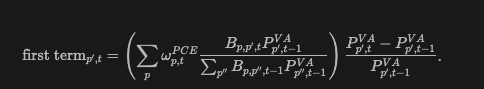

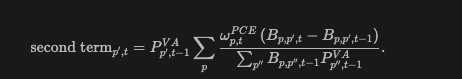

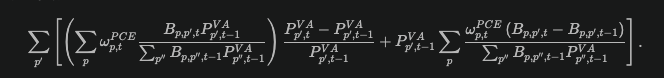

In [66]:
# LHS: observed/imputed BEA product-price inflation
pi_CPI_lhs = {}

for prev, t in zip(periods[:-1], periods[1:]):

    omega_PCE = (bea_expenditures_weights[t].reindex(products).fillna(0))

    P_t = P_wide[t].reindex(products)
    P_lag = P_wide[prev].reindex(products)

    pi_p = (P_t - P_lag) / P_lag

    pi_CPI_lhs[t] = omega_PCE @ pi_p

pi_CPI_lhs = pd.Series(pi_CPI_lhs, name="pi_CPI_lhs")

step5_rhs = {}
step5_terms_p_t = {}

for prev, t in zip(periods[:-1], periods[1:]):

    B_t = B[t]
    B_lag = B[prev]

    P_VA_lag = P_VA[prev].reindex(products)

    omega_PCE = (bea_expenditures_weights[t].reindex(products).fillna(0))

    # First RHS term: literal W * pi_VA
    W = W_p_t[t].reindex(products)
    pi_VA = pi_VA_p_t[t].reindex(products)

    W_piVA_literal = W * pi_VA

    # Second RHS term: stable V
    denominator = (B_lag * P_VA_lag).sum(axis=1)

    # B_t-1 can have 0 cells so the bottom can have zero 
    # if denominator 0 then replace with nan, x / Nan = Nan. replace Nan results with 0
    # outcome: if denominator cell zero numerator cell zero
    division = omega_PCE.div(denominator.replace(0, np.nan)).fillna(0)

    fraction_matrix = (B_t - B_lag).mul(division, axis="index")

    V_stable = P_VA_lag * fraction_matrix.sum(axis=0)

    term = W_piVA_literal + V_stable
    step5_terms_p_t[t] = term 

    step5_rhs[t] = term.sum()

step5_rhs = pd.Series(step5_rhs, name="step5_rhs")
step5_terms_p_t = pd.DataFrame(step5_terms_p_t)

In [67]:
step5_check = pd.concat([pi_CPI_lhs, step5_rhs], axis=1)
step5_check["diff"] = step5_check["pi_CPI_lhs"] - step5_check["step5_rhs"]
step5_check["abs_diff"] = step5_check["diff"].abs()
step5_check

,pi_CPI_lhs,step5_rhs,diff,abs_diff
1959-04-01,0.000000,0.000000,0.000000e+00,0.000000e+00
1959-07-01,0.000000,0.000000,0.000000e+00,0.000000e+00
1959-10-01,0.000000,0.000000,0.000000e+00,0.000000e+00
1960-01-01,0.000931,0.000931,-5.621155e-14,5.621155e-14
1960-04-01,0.005259,0.005259,1.174755e-14,1.174755e-14
...,...,...,...,...
2024-10-01,0.006812,0.006812,3.035766e-17,3.035766e-17
2025-01-01,0.008527,0.008527,1.561251e-17,1.561251e-17
2025-04-01,0.000000,0.000000,0.000000e+00,0.000000e+00
2025-07-01,0.000000,0.000000,0.000000e+00,0.000000e+00


# Find Sales

In [68]:
"""Sales Original Inversions Version without Price Adjustments"""
# # calculate sales in product and time period
# sales = pd.DataFrame({'date': pd.Series(dtype='datetime64[ns]'),
#                    'products': pd.Series(dtype='str'),
#                    'sales': pd.Series(dtype='float')})

# for date in dates:

#     gamma = gamma_monthly.get(date)
#     omega = omega_monthly.get(date)

#     # filter expenditures for the current date
#     expenditures_date = bea_expenditures_wide[date].fillna(0).to_frame("Expenditures")
#     expenditures_date = expenditures_date.sort_index()
#     expenditures_date = expenditures_date.apply(pd.to_numeric, errors='coerce')

#     gamma_series = gamma["Row_Sum"]
#     diag_matrix = np.diag(gamma_series)

#     x = np.identity(len(omega)) - (omega.T @ diag_matrix).T

#     sales_date = np.linalg.inv(x) @ expenditures_date

#     sales_date['date'] = date
#     sales_date['products'] = expenditures_date.index
#     sales_date.rename(columns={'Expenditures': 'sales'}, inplace=True)

#     sales = pd.concat([sales, sales_date], ignore_index=True)

"""Sales New Leontief Version With Price Adjustments"""
sales_parts = []

for date in periods:

    A_t = A_monthly[date]

    # Product price indexes P_t
    P_t = P_wide[date]

    # personal consumption expenditures not PCE weights
    PC_t = bea_expenditures_wide[date].fillna(0)

    # diag(P_t) @ A_t.T @ diag(P_t)^(-1)
    price_adjusted_A = (A_t.T.mul(P_t, axis="index").div(P_t, axis="columns"))

    I = pd.DataFrame(np.eye(len(products)), index=products, columns=products)

    sales_inverse = pd.DataFrame(np.linalg.inv((I - price_adjusted_A).to_numpy()), index=products, columns=products)

    sales_t = sales_inverse @ PC_t
    sales_t.name = "sales"

    sales_parts.append(
        pd.DataFrame({
            "date": date,
            "products": products,
            "sales": sales_t.to_numpy()}))

sales = pd.concat(sales_parts, ignore_index=True)

# Find Price of Value Added

In [69]:
# Use the Leontief value-added price matrix constructed above.
value_added = P_VA.copy()
value_added.index.name = "products"
value_added = value_added.reset_index().melt(
    id_vars="products",
    var_name="date",
    value_name="value_added",
)
value_added["products"] = value_added["products"].astype(str).str.strip().str.lower()
value_added["date"] = pd.to_datetime(value_added["date"])
value_added["value_added"] = pd.to_numeric(value_added["value_added"], errors="coerce")

In [70]:
calculated_all = pd.merge(left=value_added, right=sales, on=["products", "date"], how="inner")
calculated_all

,products,date,value_added,sales
0,accessories and parts,1959-01-01,28.384000,0.0
1,agricultural machinery,1959-01-01,-838.454389,0.0
2,air transportation,1959-01-01,19.182000,0.0
3,aircraft,1959-01-01,-9158.739851,0.0
4,alcohol in purchased meals,1959-01-01,9.769000,0.0
...,...,...,...,...
62439,water transportation,2025-10-01,97.475000,0.0
62440,window coverings,2025-10-01,113.037000,0.0
62441,wine,2025-10-01,108.924000,0.0
62442,women's and girls' clothing,2025-10-01,97.286000,0.0


# Sales and Value Added VAR

In [71]:
# lags = 4
# residuals_part = []

# calculated_all = pd.merge(left=value_added, right=sales, on=["products", "date"], how="inner")

# for product in P_VA.index:

#     calculated = calculated_all[calculated_all["products"] == product][
#         ["date", "value_added", "sales"]
#     ].sort_values(["date"])
#     calculated = calculated.set_index("date")

#     # Logs require positive levels.
#     # calculated = calculated[
#     #     (calculated["value_added"] > 0)
#     #     & (calculated["sales"] > 0)
#     # ]

#     calculated["value_added"] = np.log(calculated["value_added"]).diff()
#     calculated["sales"] = np.log(calculated["sales"]).diff()

#     calculated.replace([np.inf, -np.inf, np.nan], 0, inplace=True)
    
#     full_index_calc = pd.date_range(start=calculated.index.min(), end=calculated.index.max(), freq="QS")
#     #full_index_calc = pd.date_range(start=(min(periods[1:]) - pd.DateOffset(months=3 * lags)), end=max(periods[1:]), freq="QS")

#     calculated = calculated.reindex(full_index_calc)

#     # Reindex can create new NaNs.
#     # calculated.replace([np.inf, -np.inf, np.nan], 0, inplace=True)

#     model_calculated = VAR(calculated)
#     result_calculated = model_calculated.fit(lags)

#     residuals_calculated = result_calculated.resid.reset_index()
#     residuals_calculated["products"] = product
    
#     residuals_part.append(residuals_calculated)
    
# IO_residuals = pd.concat(residuals_part, ignore_index=True)
# IO_residuals.rename(columns={"index": "date", "value_added": "residual_value_added", "sales": "residual_sales"}, inplace=True)
# IO_residuals = IO_residuals.groupby(["date", "products"]).sum(min_count=1).reset_index()
# IO_residuals = IO_residuals.sort_values(["date", "products"])

In [72]:
# lags = 4
# residuals_part = []

# calculated_all = pd.merge(
#     value_added,
#     sales,
#     on=["products", "date"],
#     how="inner",
#     validate="one_to_one"
# )

# for product in P_VA.index:

#     calculated = (
#         calculated_all.loc[
#             calculated_all["products"] == product,
#             ["date", "value_added", "sales"]
#         ]
#         .sort_values("date")
#         .set_index("date")
#     )

#     # Ensure a complete quarterly calendar before identifying gaps.
#     full_index_calc = pd.date_range(
#         start=calculated.index.min(),
#         end=calculated.index.max(),
#         freq="QS"
#     )
#     calculated = calculated.reindex(full_index_calc)

#     # A level is usable only when both variables are finite and positive.
#     good_level = (
#         calculated["value_added"].gt(0)
#         & calculated["sales"].gt(0)
#         & np.isfinite(calculated["value_added"])
#         & np.isfinite(calculated["sales"])
#     )

#     if not good_level.any():
#         raise ValueError(f"{product}: no date has positive P_VA and sales")

#     first_good_date = good_level[good_level].index[0]
#     last_good_date = good_level[good_level].index[-1]

#     # Dates outside the valid span are never passed to the VAR.
#     calculated = calculated.loc[first_good_date:last_good_date].copy()
#     good_level = good_level.loc[first_good_date:last_good_date]

#     # Treat an interior invalid level as an unchanged level.
#     # This produces zero log growth during the interior gap.
#     levels_for_logs = calculated.copy()
#     levels_for_logs.loc[~good_level, ["value_added", "sales"]] = np.nan

#     with np.errstate(divide="ignore", invalid="ignore"):
#         log_levels = np.log(levels_for_logs)

#     log_levels = log_levels.ffill()

#     calculated_growth = (
#         log_levels
#         .diff()
#         .replace([np.inf, -np.inf], np.nan)
#         .fillna(0)
#     )

#     if len(calculated_growth) <= lags:
#         raise ValueError(
#             f"{product}: only {len(calculated_growth)} quarters "
#             f"between first and last valid dates"
#         )

#     if not np.isfinite(calculated_growth.to_numpy()).all():
#         raise ValueError(f"{product}: non-finite value remains before VAR")

#     model_calculated = VAR(calculated_growth)
#     result_calculated = model_calculated.fit(lags)

#     residuals_calculated = result_calculated.resid.reset_index()
#     residuals_calculated["products"] = product
#     residuals_part.append(residuals_calculated)

# IO_residuals = pd.concat(residuals_part, ignore_index=True)

# IO_residuals.rename(
#     columns={
#         "index": "date",
#         "value_added": "residual_value_added",
#         "sales": "residual_sales"
#     },
#     inplace=True
# )

# IO_residuals = (
#     IO_residuals
#     .groupby(["date", "products"])
#     .sum(min_count=1)
#     .reset_index()
#     .sort_values(["date", "products"])
# )

In [73]:
lags = 4
residuals_part = []

calculated_all = pd.merge(
    value_added,
    sales,
    on=["products", "date"],
    how="inner",
    validate="one_to_one"
)

for product in P_VA.index:

    calculated = (
        calculated_all.loc[
            calculated_all["products"] == product,
            ["date", "value_added", "sales"]
        ]
        .sort_values("date")
        .set_index("date")
    )

    # Ensure a complete quarterly calendar before identifying gaps.
    full_index_calc = pd.date_range(
        start=calculated.index.min(),
        end=calculated.index.max(),
        freq="QS"
    )
    calculated = calculated.reindex(full_index_calc)

    # Negative levels are allowed. Zero and non-finite levels are invalid
    # because the growth formula divides by the absolute current level.
    good_level = (
        calculated["value_added"].ne(0)
        & calculated["sales"].ne(0)
        & np.isfinite(calculated["value_added"])
        & np.isfinite(calculated["sales"])
    )

    if not good_level.any():
        raise ValueError(
            f"{product}: no date has finite, non-zero value_added and sales"
        )

    first_good_date = good_level[good_level].index[0]
    last_good_date = good_level[good_level].index[-1]

    # Dates outside the usable span are not passed to the VAR.
    calculated = calculated.loc[first_good_date:last_good_date].copy()
    good_level = good_level.loc[first_good_date:last_good_date]

    # Hold levels constant across interior invalid periods.
    # This produces zero growth during those periods.
    levels_for_growth = calculated.copy()
    levels_for_growth.loc[
        ~good_level, ["value_added", "sales"]
    ] = np.nan
    levels_for_growth = levels_for_growth.ffill()

    # Growth(t) = [X(t) - X(t-1)] / |X(t)|
    calculated_growth = (
        levels_for_growth.diff()
        .div(levels_for_growth.abs().replace(0, np.nan))
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
    )

    if len(calculated_growth) <= lags:
        raise ValueError(
            f"{product}: only {len(calculated_growth)} quarters "
            f"between first and last valid dates"
        )

    if not np.isfinite(calculated_growth.to_numpy()).all():
        raise ValueError(f"{product}: non-finite value remains before VAR")

    model_calculated = VAR(calculated_growth)
    result_calculated = model_calculated.fit(lags)

    residuals_calculated = result_calculated.resid.reset_index()
    residuals_calculated["products"] = product
    residuals_part.append(residuals_calculated)

IO_residuals = pd.concat(residuals_part, ignore_index=True)

IO_residuals.rename(
    columns={
        "index": "date",
        "value_added": "residual_value_added",
        "sales": "residual_sales"
    },
    inplace=True
)

IO_residuals = (
    IO_residuals
    .groupby(["date", "products"])
    .sum(min_count=1)
    .reset_index()
    .sort_values(["date", "products"])
)

In [74]:
calculated_all

,products,date,value_added,sales
0,accessories and parts,1959-01-01,28.384000,0.0
1,agricultural machinery,1959-01-01,-838.454389,0.0
2,air transportation,1959-01-01,19.182000,0.0
3,aircraft,1959-01-01,-9158.739851,0.0
4,alcohol in purchased meals,1959-01-01,9.769000,0.0
...,...,...,...,...
62439,water transportation,2025-10-01,97.475000,0.0
62440,window coverings,2025-10-01,113.037000,0.0
62441,wine,2025-10-01,108.924000,0.0
62442,women's and girls' clothing,2025-10-01,97.286000,0.0


# Price and Quantity VAR

In [75]:
lags = 4
residual_temp = []

for product in P_VA.index:

    original = bea_PQE_merged[bea_PQE_merged['products'] == product][['date', 'Prices', 'Quantities']].sort_values(['date'])
    original = original.set_index('date')

    original.dropna(inplace=True)

    # Logs require positive levels.
    original = original[(original["Prices"] > 0) & (original["Quantities"] > 0)]

    original['Prices'] = np.log(original['Prices']).diff()
    original['Quantities'] = np.log(original['Quantities']).diff()
     

    original.replace([np.inf, -np.inf], np.nan, inplace=True)
    original.dropna(inplace=True)

    full_index = pd.date_range(start=original.index.min(), end=original.index.max(), freq='QS')
    original = original.reindex(full_index)

    model_original = VAR(original)
    result_original = model_original.fit(lags)

    residuals_original = result_original.resid.reset_index()
    residuals_original['products'] = product
    
    residual_temp.append(residuals_original)
    
residuals_normal = pd.concat(residual_temp, ignore_index=True)
residuals_normal.rename(columns={'index': 'date', 'Prices': 'residual_prices', 'Quantities': 'residual_quantities'}, inplace=True)
residuals_normal = residuals_normal.groupby(['date', 'products']).sum(min_count=1).reset_index()
residuals_normal = residuals_normal.sort_values(['date', 'products'])

# Classification of Price of Value Added and Real Production

In [76]:
residuals_normal['majority_demand'] = ((residuals_normal['residual_prices'] * residuals_normal['residual_quantities']) >= 0).astype(int)
residuals_normal['majority_supply'] = ((residuals_normal['residual_prices'] * residuals_normal['residual_quantities']) < 0).astype(int)

IO_residuals['majority_demand_a'] = ((IO_residuals['residual_value_added'] * IO_residuals['residual_sales']) >= 0).astype(int)
IO_residuals['majority_supply_a'] = ((IO_residuals['residual_value_added'] * IO_residuals['residual_sales']) < 0).astype(int)

In [77]:
def plot_graphs(
    data,
    step5_lhs,
    plot_title,
    plot_text="",
):
    """
    Plot annual demand and supply contributions.

    Dotted line: annual demand + annual supply.
    Black line: annualized Step 5 LHS.
    """
    data = data.sort_index().copy()

    # Annualize the quarterly Step 5 LHS before restricting the plot dates.
    cpi_quarterly = step5_lhs.copy()
    cpi_quarterly.index = pd.to_datetime(cpi_quarterly.index)
    cpi_quarterly = (
        cpi_quarterly
        .sort_index()
        .reindex(data.index)
        .astype(float)
    )

    # The value dated t uses quarters t-4 through t-1.
    annual_cpi = (
        cpi_quarterly
        .add(1)
        .shift(1)
        .rolling(window=4, min_periods=4)
        .apply(np.prod, raw=True)
        .sub(1)
        .mul(100)
    )

    plot_data = data.loc[
        data.index >= pd.Timestamp("1970-01-01")
    ].copy()

    # Match the previous function's treatment of the final observation.
    plot_data = plot_data.iloc[:-1]
    annual_cpi = annual_cpi.reindex(plot_data.index)

    demand = plot_data["annual_demand_inflation"]
    supply = plot_data["annual_supply_inflation"]

    demand_positive = demand.clip(lower=0)
    supply_positive = supply.clip(lower=0)
    demand_negative = demand.clip(upper=0)
    supply_negative = supply.clip(upper=0)

    # Supply is already signed, so demand + supply uses addition.
    demand_supply_total = demand + supply

    fig, ax = plt.subplots(figsize=(26, 12))

    ax.stackplot(
        plot_data.index,
        demand_positive,
        supply_positive,
        colors=["#008000", "#FF0000"],
        labels=["Demand", "Supply"],
    )

    ax.stackplot(
        plot_data.index,
        demand_negative,
        supply_negative,
        colors=["#008000", "#FF0000"],
    )

    ax.plot(
        plot_data.index,
        demand_supply_total,
        color="#666666",
        linestyle=":",
        linewidth=2,
        label="Demand + Supply",
    )

    ax.plot(
        plot_data.index,
        annual_cpi,
        color="black",
        linewidth=2.5,
        label="Step 5 LHS CPI",
    )

    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_xlabel("Date")
    ax.set_ylabel("Annual inflation contribution (percentage points)")
    ax.set_title(plot_title)
    ax.legend()

    if plot_text:
        ax.text(
            0.02,
            0.95,
            plot_text,
            transform=ax.transAxes,
            fontsize=9,
            verticalalignment="top",
            bbox=dict(facecolor="white", alpha=0.8),
        )

    fig.tight_layout()
    return fig, ax

In [78]:
# IO VAR classifictions
D_IO = IO_residuals.pivot(index='products', columns='date', values='majority_demand_a')

# Shapiro VAR classifictions
D_shapiro = residuals_normal.pivot(index='products', columns='date', values='majority_demand')

In [79]:
D_shapiro

date,1960-04-01,1960-07-01,1960-10-01,1961-01-01,1961-04-01,1961-07-01,1961-10-01,1962-01-01,1962-04-01,1962-07-01,...,2023-07-01,2023-10-01,2024-01-01,2024-04-01,2024-07-01,2024-10-01,2025-01-01,2025-04-01,2025-07-01,2025-10-01
products,,,,,,,,,,,,,,,,,,,,,
accessories and parts,NaN,NaN,NaN,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN
agricultural machinery,0.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,...,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
air transportation,NaN,NaN,NaN,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,NaN,NaN,NaN
aircraft,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
alcohol in purchased meals,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
water transportation,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,1.0,1.0,0.0,0.0,NaN,NaN,NaN
window coverings,NaN,NaN,NaN,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,NaN,NaN,NaN
wine,NaN,NaN,NaN,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN


In [114]:
# Identify product-date observations that contribute to Step 5 inflation
# but do not receive an IO classification.

contribution_tolerance = 1e-12

terms = step5_terms_p_t.copy()
terms.index.name = "products"
terms.columns.name = "date"

classifications = D_IO.reindex(
    index=terms.index,
    columns=terms.columns
)

pva = P_VA.reindex(
    index=terms.index,
    columns=terms.columns
)

sales_wide = (
    sales.pivot(index="products", columns="date", values="sales")
    .reindex(index=terms.index, columns=terms.columns)
)

def matrix_to_long(df, value_name):
    return (
        df.rename_axis(index="products", columns="date")
        .reset_index()
        .melt(
            id_vars="products",
            var_name="date",
            value_name=value_name
        )
    )

classification_audit = (
    matrix_to_long(terms, "inflation_contribution")
    .merge(
        matrix_to_long(classifications, "IO_classification"),
        on=["products", "date"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        matrix_to_long(pva, "P_VA"),
        on=["products", "date"],
        how="left",
        validate="one_to_one"
    )
    .merge(
        matrix_to_long(sales_wide, "sales"),
        on=["products", "date"],
        how="left",
        validate="one_to_one"
    )
)

classification_audit["P_VA_bad_for_log"] = (
    classification_audit["P_VA"].isna()
    | ~np.isfinite(classification_audit["P_VA"])
    | classification_audit["P_VA"].le(0)
)

classification_audit["sales_bad_for_log"] = (
    classification_audit["sales"].isna()
    | ~np.isfinite(classification_audit["sales"])
    | classification_audit["sales"].le(0)
)

unclassified_contributors = classification_audit.loc[
    classification_audit["inflation_contribution"].abs().gt(contribution_tolerance)
    & classification_audit["IO_classification"].isna()
].copy()

unclassified_contributors["absolute_contribution"] = (
    unclassified_contributors["inflation_contribution"].abs()
)

unclassified_contributors = unclassified_contributors.sort_values(
    ["date", "absolute_contribution"],
    ascending=[True, False]
).reset_index(drop=True)

print("Product-date observations:", len(unclassified_contributors))
print("Unique products:", unclassified_contributors["products"].nunique())
print("Unique dates:", unclassified_contributors["date"].nunique())

unclassified_contributors

Product-date observations: 730
Unique products: 233
Unique dates: 31


,products,date,inflation_contribution,IO_classification,P_VA,sales,P_VA_bad_for_log,sales_bad_for_log,absolute_contribution
0,computers and peripheral equipment,1960-01-01 00:00:00,-21.051070,NaN,766268.266398,2.665877e+07,False,False,21.051070
1,tobacco,1960-01-01 00:00:00,1.632487,NaN,-1419.971095,7.017250e+03,True,False,1.632487
2,life insurance,1960-01-01 00:00:00,1.210703,NaN,-3859.302837,3.571701e+03,True,False,1.210703
3,physician services,1960-01-01 00:00:00,0.816669,NaN,-2027.324245,5.715346e+03,True,False,0.816669
4,legal services,1960-01-01 00:00:00,0.765016,NaN,-2102.082261,2.212905e+03,True,False,0.765016
...,...,...,...,...,...,...,...,...,...
725,"tenant-occupied, including landlord durables",2002-01-01 00:00:00,0.000029,NaN,63.763460,2.404862e+05,False,False,0.000029
726,tenant-occupied stationary homes,2002-01-01 00:00:00,-0.000028,NaN,63.423000,0.000000e+00,False,True,0.000028
727,"tenant-occupied, including landlord durables",2002-04-01 00:00:00,0.000246,NaN,64.257906,2.404188e+05,False,False,0.000246
728,"tenant-occupied, including landlord durables",2002-07-01 00:00:00,0.000226,NaN,64.720311,2.405379e+05,False,False,0.000226


In [115]:
(unclassified_contributors["sales"] == 0).sum()

np.int64(2)

# 7. Inflation Contribution based on Classification

In [116]:
PI_t = (P_wide.div(P_wide.shift(1, axis=1)).sub(1))

# Shaprio 
inflation_parts_shapiro = {}

for date in D_shapiro.columns:

    current_demand = D_shapiro[date].reindex(products)
    current_supply = 1 - current_demand

    current_omega_PCE = (bea_expenditures_weights[date].reindex(products).fillna(0))
    current_price_chnage = PI_t[date].reindex(products)
    current_inflation = current_omega_PCE * current_price_chnage

    demand_inflation = (current_demand * current_inflation).sum()
    supply_inflation = (current_supply * current_inflation).sum()
    omitted_inflation = current_inflation[current_demand.isna()].sum()

    inflation_parts_shapiro[date] = [demand_inflation, supply_inflation, omitted_inflation]

inflation_shapiro_final = pd.DataFrame(inflation_parts_shapiro,index=["demand_inflation", "supply_inflation", "omitted_inflation"]).T
inflation_shapiro_final["total"] = (inflation_shapiro_final["demand_inflation"] + inflation_shapiro_final["supply_inflation"] + inflation_shapiro_final["omitted_inflation"])

# ShapirIO 
inflation_parts_IO = {}

for date in D_IO.columns:

    current_demand = D_IO[date].reindex(products)
    current_supply = 1 - current_demand
    current_term = step5_terms_p_t[date].reindex(products)

    demand_inflation = (current_demand * current_term).sum()
    supply_inflation = (current_supply * current_term).sum()
    omitted_inflation = current_term[current_demand.isna()].sum()

    inflation_parts_IO[date] = [demand_inflation, supply_inflation, omitted_inflation]

inflation_IO_final = pd.DataFrame(inflation_parts_IO, index=["demand_inflation", "supply_inflation", "omitted_inflation"]).T
inflation_IO_final["total"] = (inflation_IO_final["demand_inflation"] + inflation_IO_final["supply_inflation"] + inflation_IO_final["omitted_inflation"])

# Quarter to Annual Inflation

In [117]:
# # IO Classification - Anual Supply Inflation
# inflation_IO_final['annual_supply_inflation'] = (
#     (inflation_IO_final['supply_inflation'].add(1).shift(1).rolling(window=4, min_periods=4).apply(np.prod, raw=True) - 1) * 100
# )
# # IO Classification - Anual Demand Inflation
# inflation_IO_final['annual_demand_inflation'] = (
#     (inflation_IO_final['demand_inflation'].add(1).shift(1).rolling(window=4, min_periods=4).apply(np.prod, raw=True) - 1) * 100
# )
# # Shapiro Classification - Anual Supply Inflation
# inflation_shapiro_final['annual_supply_inflation'] = (
#     (inflation_shapiro_final['supply_inflation'].add(1).shift(1).rolling(window=4, min_periods=4).apply(np.prod, raw=True) - 1) * 100
# )
# # Shapiro Classification - Anual Demand Inflation
# inflation_shapiro_final['annual_demand_inflation'] = (
#     (inflation_shapiro_final['demand_inflation'].add(1).shift(1).rolling(window=4, min_periods=4).apply(np.prod, raw=True) - 1) * 100
# )


# inflation_IO_final['annual_omitted_inflation'] = (
#     (inflation_IO_final['omitted_inflation'].add(1).shift(1).rolling(window=4, min_periods=4).apply(np.prod, raw=True) - 1) * 100
# )

In [118]:
def annualize_additive_components(data, component_columns):
    """
    Construct annual contributions that add exactly to annual total inflation.

    This preserves the existing convention that the annual value dated t uses
    the four quarters t-4 through t-1.
    """
    result = data.copy().sort_index()

    quarterly_total = result[component_columns].sum(
        axis=1,
        min_count=len(component_columns),
    )

    total_lag1 = quarterly_total.shift(1)
    total_lag2 = quarterly_total.shift(2)
    total_lag3 = quarterly_total.shift(3)
    total_lag4 = quarterly_total.shift(4)

    for column in component_columns:
        component = result[column]

        result[f"annual_{column}"] = 100 * (
            component.shift(4)
            * (1 + total_lag3)
            * (1 + total_lag2)
            * (1 + total_lag1)
            + component.shift(3)
            * (1 + total_lag2)
            * (1 + total_lag1)
            + component.shift(2)
            * (1 + total_lag1)
            + component.shift(1)
        )

    result["annual_total_inflation"] = 100 * (
        (1 + total_lag4)
        * (1 + total_lag3)
        * (1 + total_lag2)
        * (1 + total_lag1)
        - 1
    )

    annual_components = [
        f"annual_{column}" for column in component_columns
    ]

    annual_component_sum = result[annual_components].sum(
        axis=1,
        min_count=len(annual_components),
    )

    print(
        "Maximum annual decomposition error:",
        (annual_component_sum - result["annual_total_inflation"]).abs().max(),
    )

    return result


def plot_graphs_with_unclassified(
    data,
    step5_lhs,
    plot_title,
    plot_text="",
):
    """
    Green: demand.
    Red: supply.
    Blue: unclassified.
    Dotted: demand + supply.
    Black: annualized Step 5 LHS CPI.
    """
    data = data.sort_index().copy()

    cpi_quarterly = step5_lhs.copy()
    cpi_quarterly.index = pd.to_datetime(cpi_quarterly.index)

    cpi_quarterly = (
        cpi_quarterly
        .sort_index()
        .reindex(data.index)
        .astype(float)
    )

    annual_cpi = (
        cpi_quarterly
        .add(1)
        .shift(1)
        .rolling(4, min_periods=4)
        .apply(np.prod, raw=True)
        .sub(1)
        .mul(100)
    )

    plot_data = data.loc[
        data.index >= pd.Timestamp("1970-01-01")
    ].iloc[:-1].copy()

    annual_cpi = annual_cpi.reindex(plot_data.index)

    demand = plot_data["annual_demand_inflation"]
    supply = plot_data["annual_supply_inflation"]
    unclassified = plot_data["annual_omitted_inflation"]

    components = [demand, supply, unclassified]
    colors = ["#008000", "#FF0000", "#1F77B4"]
    labels = ["Demand", "Supply", "Unclassified"]

    fig, ax = plt.subplots(figsize=(26, 12))

    ax.stackplot(
        plot_data.index,
        *[component.clip(lower=0) for component in components],
        colors=colors,
        labels=labels,
    )

    ax.stackplot(
        plot_data.index,
        *[component.clip(upper=0) for component in components],
        colors=colors,
    )

    classified_total = demand + supply

    ax.plot(
        plot_data.index,
        classified_total,
        color="#666666",
        linestyle=":",
        linewidth=2,
        label="Demand + Supply",
    )

    ax.plot(
        plot_data.index,
        annual_cpi,
        color="black",
        linewidth=2.5,
        label="Step 5 LHS CPI",
    )

    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_xlabel("Date")
    ax.set_ylabel(
        "Annual inflation contribution (percentage points)"
    )
    ax.set_title(plot_title)
    ax.legend()

    if plot_text:
        ax.text(
            0.02,
            0.95,
            plot_text,
            transform=ax.transAxes,
            fontsize=9,
            verticalalignment="top",
            bbox=dict(facecolor="white", alpha=0.8),
        )

    fig.tight_layout()
    return fig, ax

In [119]:
inflation_IO_final = annualize_additive_components(
    inflation_IO_final,
    [
        "demand_inflation",
        "supply_inflation",
        "omitted_inflation",
    ])

inflation_shapiro_final = annualize_additive_components(
    inflation_shapiro_final,
    [
        "demand_inflation",
        "supply_inflation",
        "omitted_inflation"
    ])

Maximum annual decomposition error: 4.840572387365683e-13
Maximum annual decomposition error: 4.551914400963142e-14


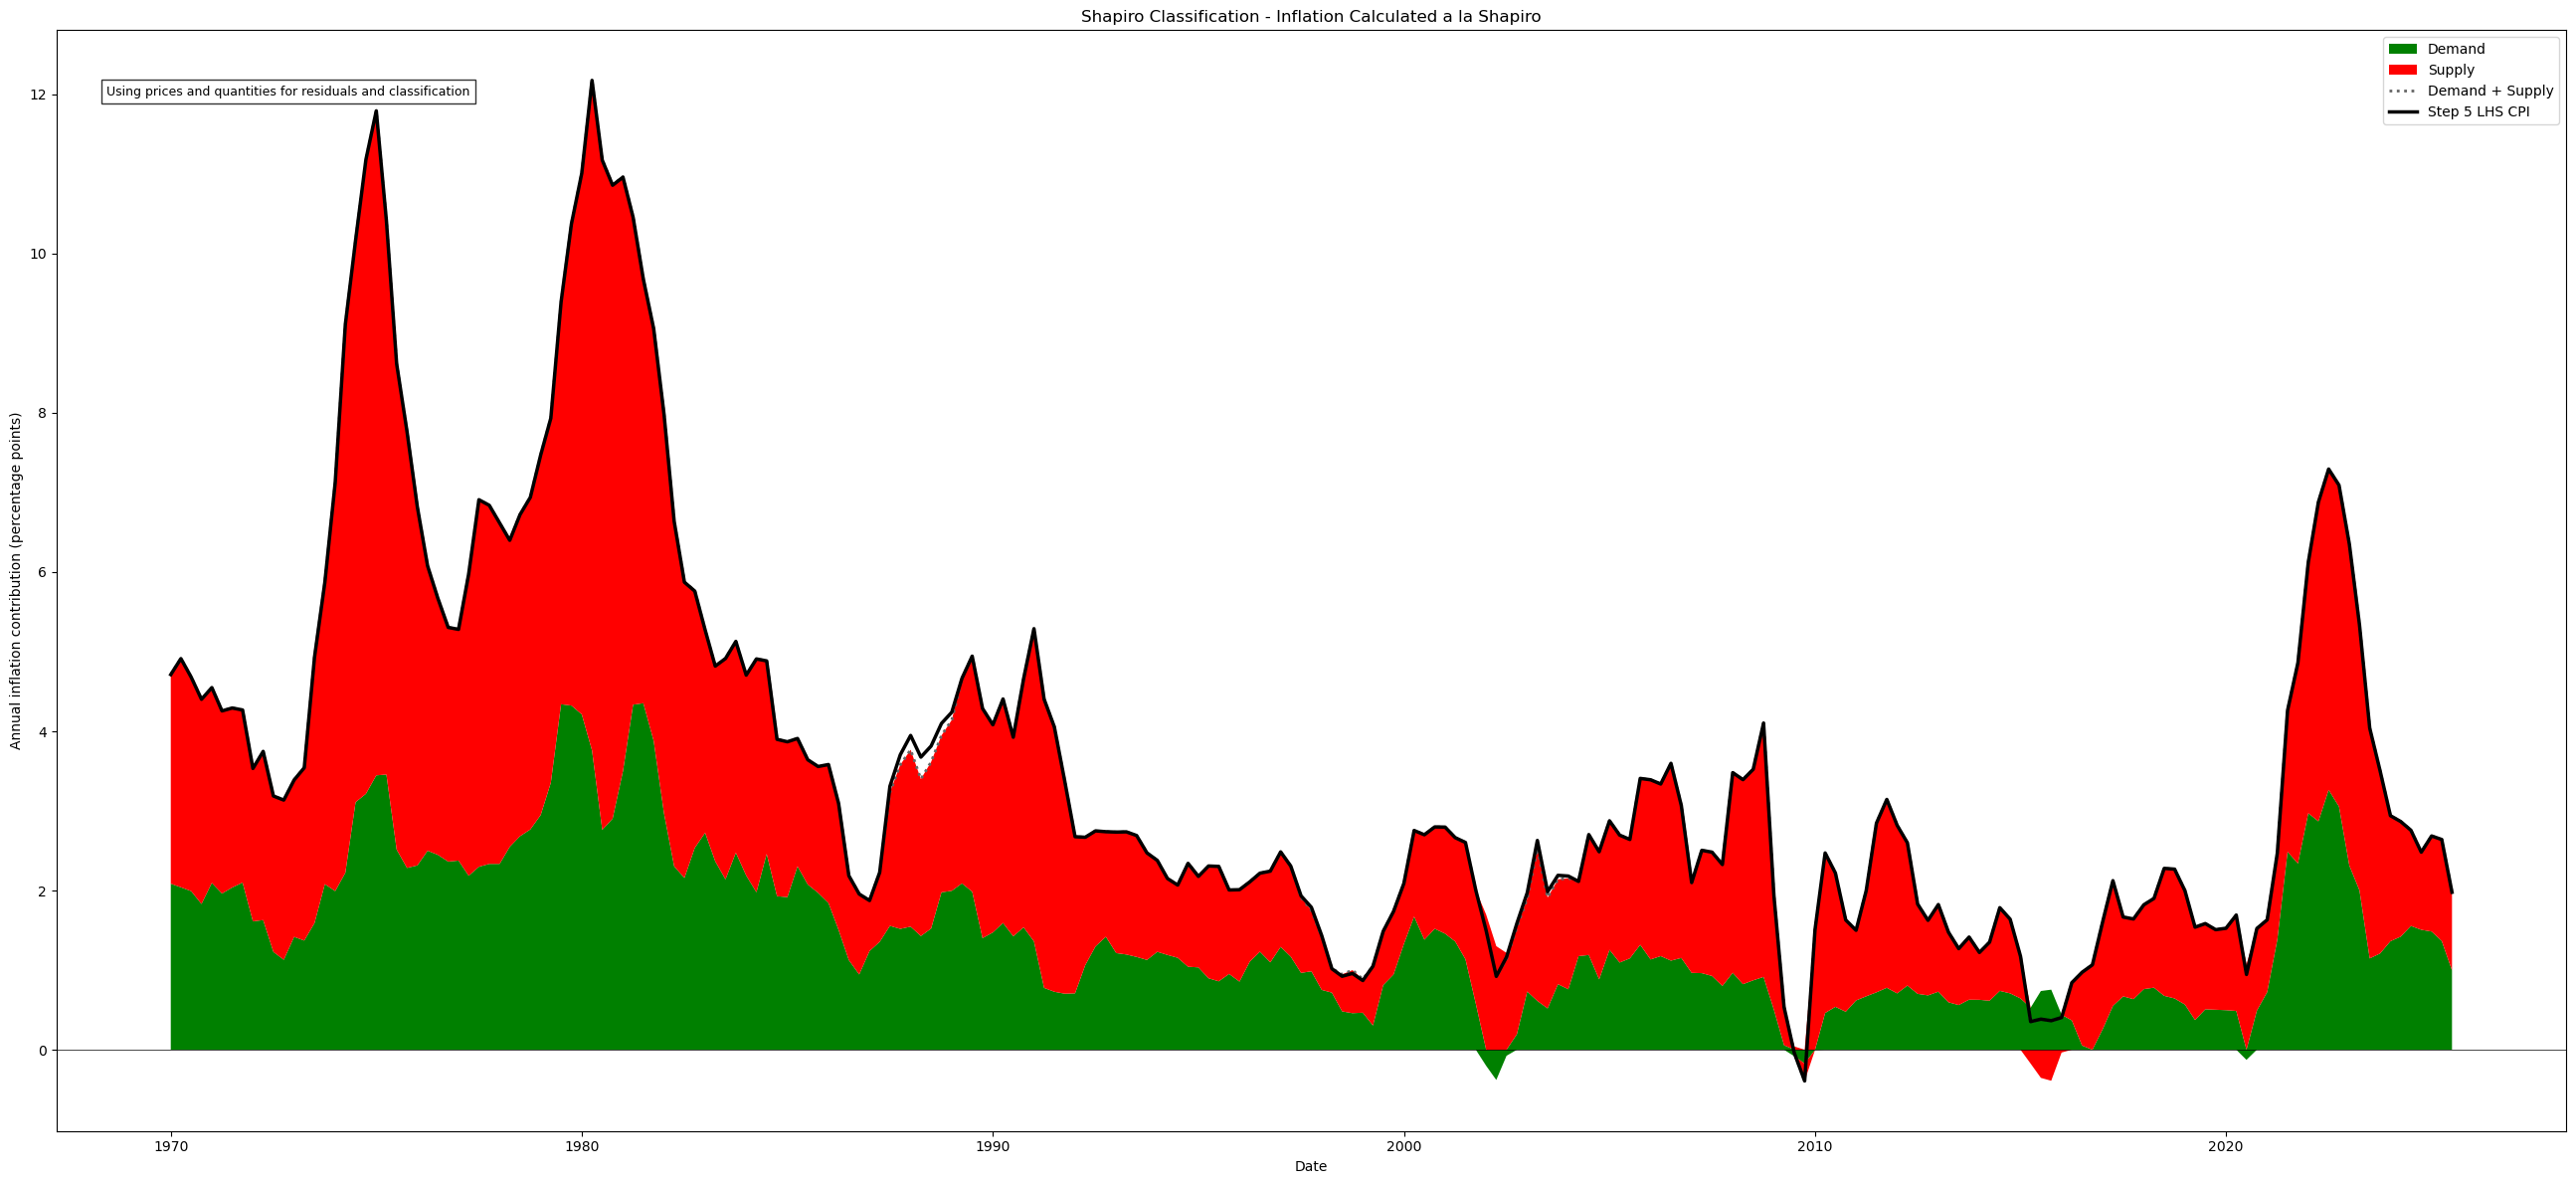

In [120]:
fig, ax = plot_graphs(
    inflation_shapiro_final,
    pi_CPI_lhs,
    "Shapiro Classification - Inflation Calculated a la Shapiro",
    "Using prices and quantities for residuals and classification",
)

plt.show()

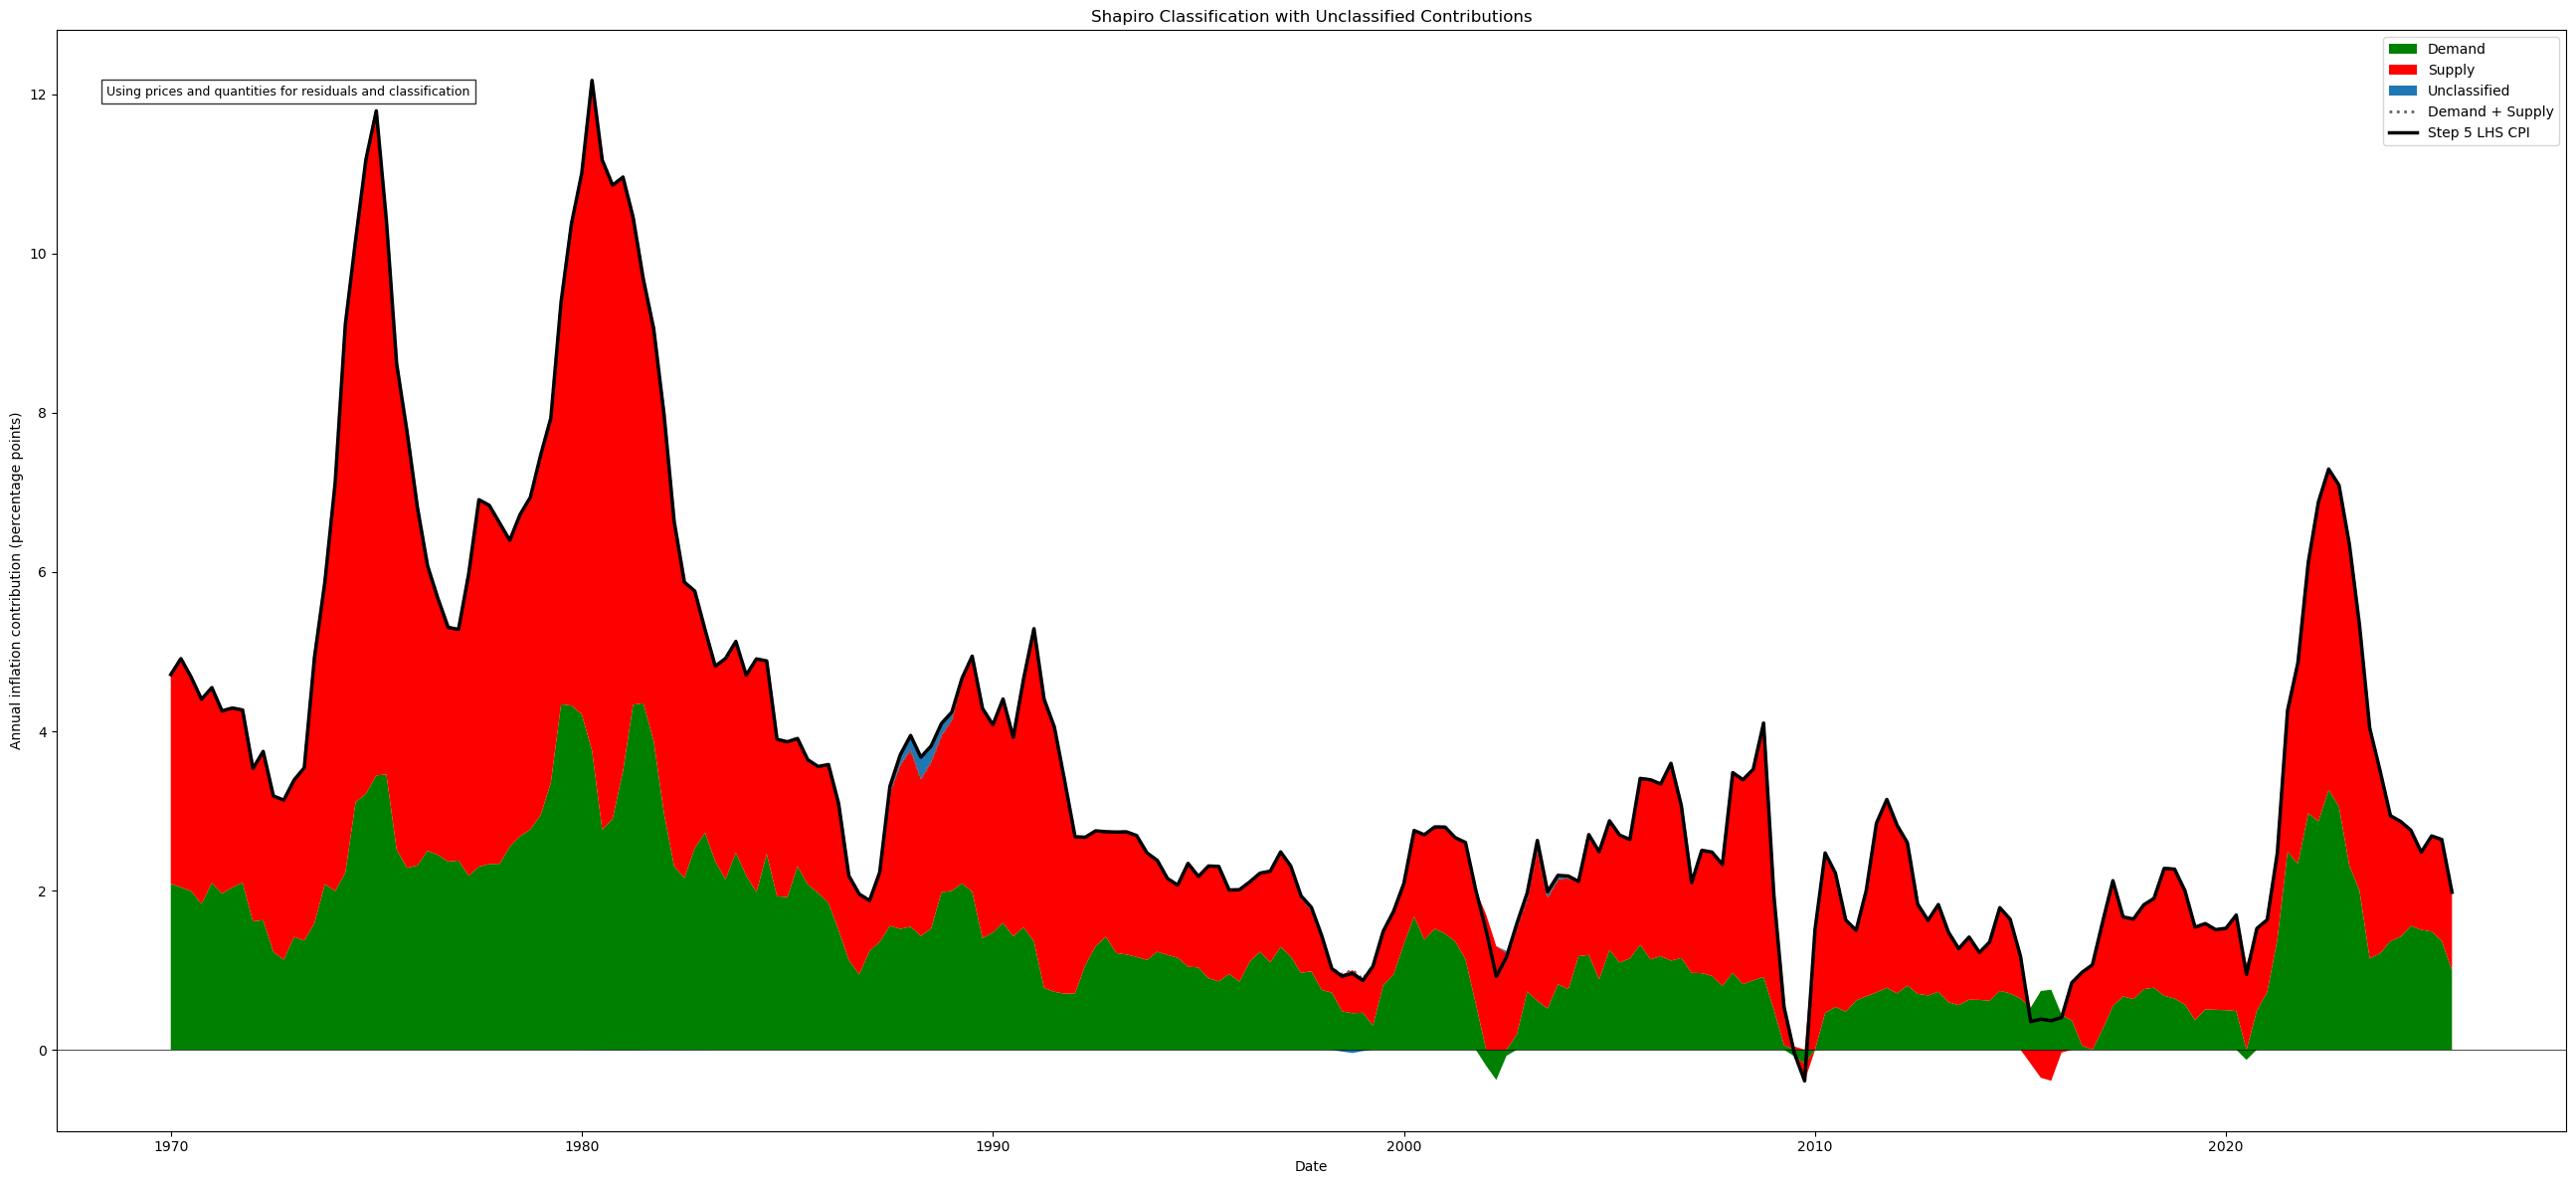

In [121]:
fig, ax = plot_graphs_with_unclassified(
    inflation_shapiro_final,
    pi_CPI_lhs,
    "Shapiro Classification with Unclassified Contributions",
    "Using prices and quantities for residuals and classification",
)

plt.show()

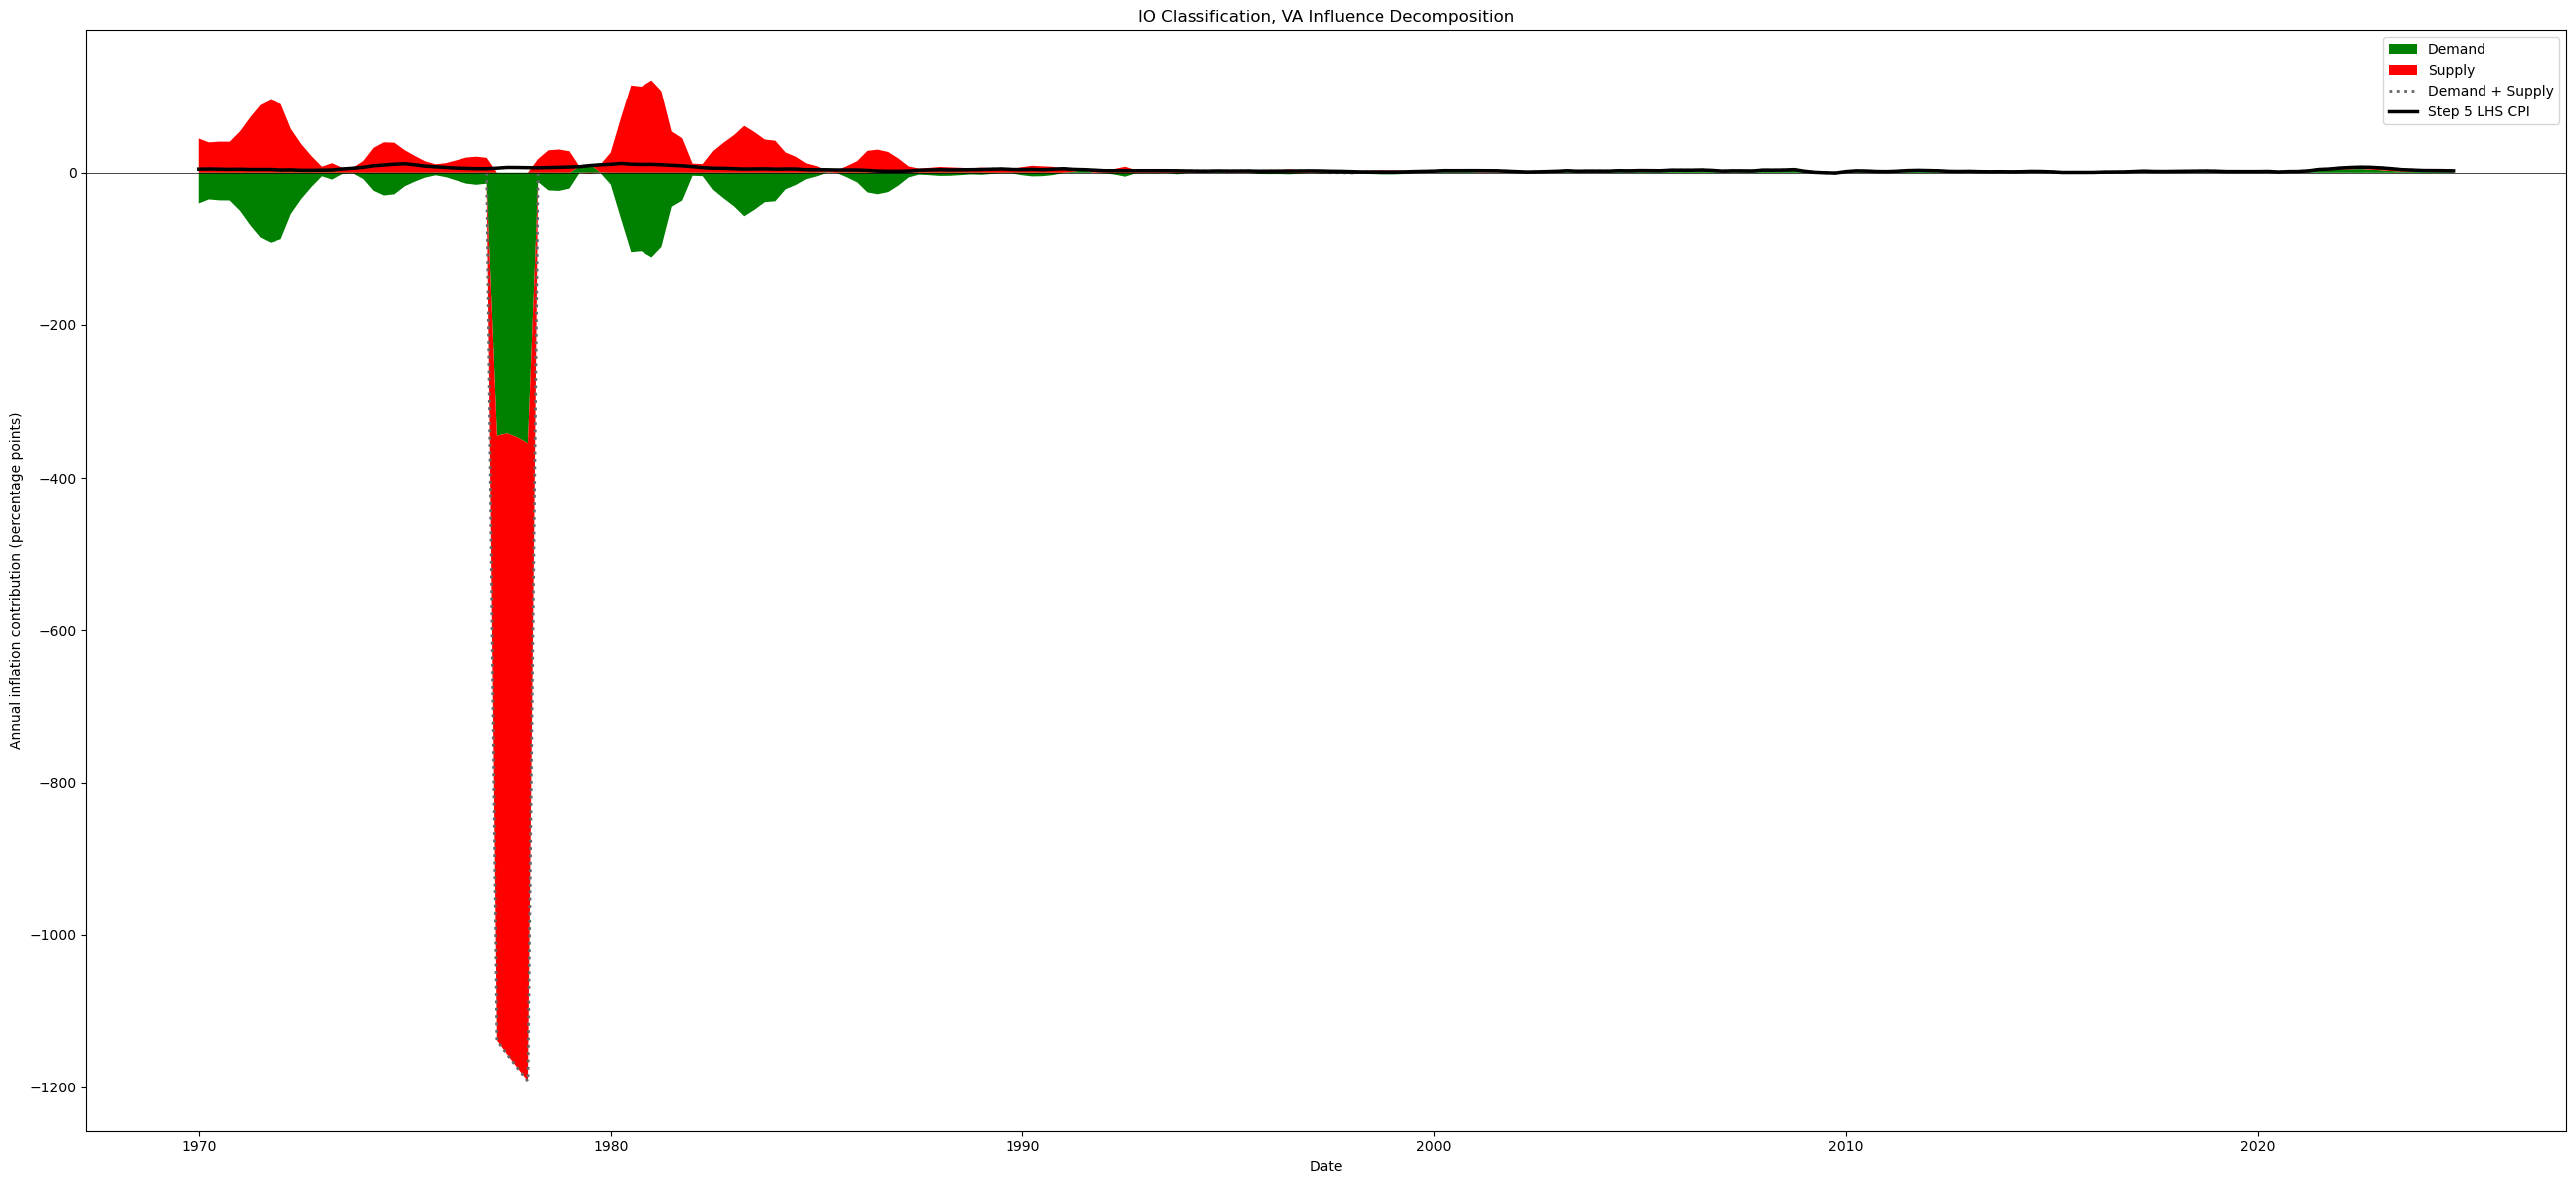

In [122]:
fig, ax = plot_graphs(
    inflation_IO_final,
    pi_CPI_lhs,
    "IO Classification, VA Influence Decomposition",
)

plt.show()

In [123]:
import plotly.graph_objects as go

def plot_graphs_interactive(
    data,
    plot_title,
    plot_text="",
    renderer=None,
):
    """Interactive equivalent of plot_graphs."""

    data = (
        data.loc[data.index >= pd.Timestamp("1970-01-01")]
        .sort_index()
        .copy()
    )

    # Match the original plot_graphs behavior.
    data = data.iloc[:-1]

    demand = data["annual_demand_inflation"]
    supply = data["annual_supply_inflation"]

    components = [
        ("Demand", demand, "#008000"),
        ("Supply", supply, "#FF0000"),
    ]

    # IO has an unclassified component; Shapiro may not.
    has_omitted = "annual_omitted_inflation" in data.columns

    if has_omitted:
        omitted = data["annual_omitted_inflation"]
        components.append(("Unclassified", omitted, "#808080"))

    fig = go.Figure()

    # Positive stack: provides the single tooltip entry.
    for name, values, color in components:
        fig.add_trace(
            go.Scatter(
                x=data.index,
                y=values.clip(lower=0),
                customdata=values,
                stackgroup="positive",
                mode="none",
                fillcolor=color,
                name=name,
                hovertemplate=f"{name}: %{{customdata:.3f}}%<extra></extra>",
            )
        )

    # Negative stack: still drawn, but omitted from the tooltip.
    for name, values, color in components:
        fig.add_trace(
            go.Scatter(
                x=data.index,
                y=values.clip(upper=0),
                stackgroup="negative",
                mode="none",
                fillcolor=color,
                name=name,
                showlegend=False,
                hoverinfo="skip",
            )
        )

    # Plot annual total lines if the column was created.
    if "annual_total_inflation" in data.columns:
        split_total = demand + supply
        split_name = "Demand + Supply"

        if has_omitted:
            split_total = split_total + omitted
            split_name += " + Unclassified"

        fig.add_trace(
            go.Scatter(
                x=data.index,
                y=split_total,
                mode="lines",
                name=split_name,
                line=dict(
                    color="#666666",
                    width=1.5,
                    dash="dash",
                ),
                hovertemplate=f"{split_name}: %{{y:.3f}}%<extra></extra>",
            )
        )

        fig.add_trace(
            go.Scatter(
                x=data.index,
                y=data["annual_total_inflation"],
                mode="lines",
                name="CPI",
                line=dict(color="black", width=3),
                hovertemplate="CPI: %{y:.3f}%<extra></extra>",
            )
        )

    if plot_text:
        fig.add_annotation(
            x=0.02,
            y=0.95,
            xref="paper",
            yref="paper",
            text=plot_text.replace("\n", "<br>"),
            showarrow=False,
            align="left",
            bgcolor="rgba(255,255,255,0.8)",
            bordercolor="#999999",
        )

    fig.update_layout(
        title=plot_title,
        xaxis_title="Date",
        yaxis_title="Inflation",
        hovermode="x unified",
        dragmode="zoom",
        height=750,
        legend=dict(x=1, y=1),
    )

    fig.update_yaxes(
    range=[-10, 20],
    fixedrange=False,
    )

    if renderer is None:
        fig.show()
    else:
        fig.show(renderer=renderer)

    return fig

In [124]:
fig = plot_graphs_interactive(inflation_IO_final, "IO Classification, VA Influence Decomposition")

In [125]:
import plotly.graph_objects as go


def plot_quarterly_graphs_interactive(
    data,
    plot_title,
    plot_text="",
    step5_lhs=None,
):
    """Plot quarterly demand, supply, and optional unclassified contributions."""

    data = (
        data.loc[data.index >= pd.Timestamp("1970-01-01")]
        .sort_index()
        .copy()
    )

    # Keep this if the final observation is an incomplete quarter.
    data = data.iloc[:-1]

    components = [
        ("Demand", data["demand_inflation"], "#008000"),
        ("Supply", data["supply_inflation"], "#FF0000"),
    ]

    if "omitted_inflation" in data.columns:
        components.append(
            (
                "Unclassified",
                data["omitted_inflation"],
                "#808080",
            )
        )

    fig = go.Figure()

    # Positive areas. The original signed value supplies the tooltip.
    for name, values, color in components:
        fig.add_trace(
            go.Scatter(
                x=data.index,
                y=values.clip(lower=0),
                customdata=values,
                stackgroup="positive",
                mode="none",
                fillcolor=color,
                name=name,
                hovertemplate=(
                    f"{name}: %{{customdata:.3f}}"
                    "<extra></extra>"
                ),
            )
        )

    # Negative areas. These are hidden from the tooltip to avoid duplicates.
    for name, values, color in components:
        fig.add_trace(
            go.Scatter(
                x=data.index,
                y=values.clip(upper=0),
                stackgroup="negative",
                mode="none",
                fillcolor=color,
                name=name,
                showlegend=False,
                hoverinfo="skip",
            )
        )

    # Recombined Step 5 RHS.
    if "total" in data.columns:
        rhs_total = data["total"] 

    fig.add_trace(
        go.Scatter(
            x=data.index,
            y=rhs_total,
            mode="lines",
            name="Supply + Demand + Unclassified",
            line=dict(
                color="#666666",
                width=2,
                dash="dash",
            ),
            hovertemplate=(
                "Supply + Demand + Unclassified: %{y:.3f}"
                "<extra></extra>"
            ),
        )
    )

    # Direct product-price calculation from the Step 5 LHS.
    if step5_lhs is not None:
        lhs_total = (
            step5_lhs
            .reindex(data.index)
            .astype(float)
        )

        fig.add_trace(
            go.Scatter(
                x=data.index,
                y=lhs_total,
                mode="lines",
                name="Step 5 LHS",
                line=dict(color="black", width=3),
                hovertemplate=(
                    "Step 5 LHS: %{y:.3f}"
                    "<extra></extra>"
                ),
            )
        )

    if plot_text:
        fig.add_annotation(
            x=0.02,
            y=0.95,
            xref="paper",
            yref="paper",
            text=plot_text.replace("\n", "<br>"),
            showarrow=False,
            align="left",
            bgcolor="rgba(255,255,255,0.8)",
            bordercolor="#999999",
        )

    fig.update_layout(
        title=plot_title,
        xaxis_title="Date",
        yaxis_title="Quarterly inflation contribution",
        hovermode="x unified",
        dragmode="zoom",
        height=750,
        legend=dict(x=1, y=1),
    )

    fig.update_xaxes(
        rangeslider_visible=True,
        modebardisable="zoominout",
    )

    # The x-range slider otherwise locks the y-axis.
    fig.update_yaxes(
        fixedrange=False,
    )

    return fig

In [126]:
quarterly_IO_fig = plot_quarterly_graphs_interactive(
    inflation_IO_final,
    "IO Classification: Quarterly Inflation Contributions",
    step5_lhs=pi_CPI_lhs,
)

quarterly_IO_fig.show()